# 05 - Visualizaciones

Las siete figuras del trabajo. Cada una se genera en dos versiones:

- **Clara**, con fondo blanco, para el documento.
- **Oscura**, con fondo transparente, para las diapositivas del video de defensa.

Las dos leen los mismos datos y dibujan lo mismo: solo cambian la paleta y el guardado.
La version oscura reutiliza las variables que calcula la clara, asi que hay que
ejecutarlas en orden.

Los apartados 1 a 4 preparan el entorno y hay que ejecutarlos antes que cualquier figura.
Las imagenes se guardan en `images/` y los datos salen de los ficheros que generan los
notebooks 02 y 03.

*La figura de la simulacion contrafactual no esta aqui: se genera en el notebook 06, junto
al analisis que la produce.*

## 1. Configuracion comun

Rutas, librerias y paleta de colores del proyecto.

In [1]:
# Subimos a la carpeta raiz del proyecto para que las rutas relativas funcionen
import os
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

# Importamos pandas para manejar los datos
import pandas as pd
# Importamos numpy para calculos numericos
import numpy as np
# Importamos matplotlib para construir las figuras
import matplotlib.pyplot as plt
# Importamos las herramientas de dibujo de campos de futbol
from mplsoccer import VerticalPitch, Pitch, PyPizza
# Importamos os para gestionar carpetas
import os

# Creamos la carpeta de imagenes si no existe
os.makedirs("images", exist_ok=True)

# Definimos la paleta de colores del proyecto
FONDO = "#0d1420"
TEXTO = "#e8eef5"
TEXTO_SUAVE = "#7f8fa3"
LINEA = "#3a4a5f"
ROJO_MALLORCA = "#c8102e"
AZUL = "#4a9eff"
VERDE = "#2ecc71"

# Aplicamos el estilo oscuro por defecto a todas las figuras
plt.rcParams["figure.facecolor"] = FONDO
plt.rcParams["axes.facecolor"] = FONDO
plt.rcParams["text.color"] = TEXTO
plt.rcParams["axes.labelcolor"] = TEXTO
plt.rcParams["xtick.color"] = TEXTO_SUAVE
plt.rcParams["ytick.color"] = TEXTO_SUAVE
plt.rcParams["axes.edgecolor"] = LINEA

# Definimos la nota de fuente que se anade al pie de cada grafico
FUENTE = "Datos: Understat, FBref y WhoScored (LaLiga 2025/26)"

# Confirmamos que la configuracion se ha aplicado
print("Configuracion cargada")

Configuracion cargada


## 2. Carga de datos

Los ficheros que usan varias figuras.

In [2]:
# Cargamos la tabla de equipos en formato largo
largo = pd.read_csv("data/equipos_largo_laliga_2526.csv")

# Cargamos la tabla de jugadores con metricas defensivas y ofensivas
jug = pd.read_csv("data/jugadores_eventos_ofensivo_laliga_2526.csv")

# Comprobamos la carga
print("Equipos por partido:", largo.shape)
print("Jugadores:", jug.shape)

Equipos por partido: (760, 18)
Jugadores: (324, 62)


## 3. Estilo y tipografia

Fuentes y ajustes de dibujo comunes a todas las figuras.

In [3]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager

# Localizamos la raiz del proyecto sin depender del directorio actual
RAIZ = Path.cwd()
if RAIZ.name == "notebooks":
    RAIZ = RAIZ.parent

# Carpetas de datos y de figuras, siempre en rutas absolutas
CARPETA_DATOS = RAIZ / "data"
CARPETA_IMAGENES = RAIZ / "images"
CARPETA_IMAGENES.mkdir(exist_ok=True)

print("raiz del proyecto:", RAIZ.name)
print("las figuras se guardan en:", CARPETA_IMAGENES.relative_to(RAIZ))

# Paleta validada para fondo blanco e impresion en papel
COLORES = {
    "mallorca": "#C8102E",
    "comparador": "#1155CC",
    "tercero": "#B07400",
    "resto": "#D5D9DD",
    "mediana": "#6B7280",
    "texto": "#1A1A1A",
}

# Rampa de un solo tono para los mapas de calor
RAMPA_ROJA = ["#FBEAED", "#F0B8C1", "#E07A8B", "#C8102E", "#7A0A1C"]

# Usamos Raleway si esta instalada, que es la tipografia de la memoria
disponibles = {f.name for f in font_manager.fontManager.ttflist}
FUENTE = "Raleway" if "Raleway" in disponibles else "DejaVu Sans"
print("fuente en uso:", FUENTE)

# Estilo comun para que todas las figuras parezcan del mismo trabajo
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "font.family": FUENTE,
    "font.size": 10,
    "text.color": COLORES["texto"],
    "axes.labelcolor": COLORES["texto"],
    "axes.edgecolor": COLORES["mediana"],
    "axes.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": COLORES["mediana"],
    "ytick.color": COLORES["mediana"],
    "grid.color": "#EDEFF1",
    "grid.linewidth": 0.8,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "savefig.facecolor": "white",
})

# Ancho estandar: 16 cm, que es lo que cabe entre los margenes de 3 cm
ANCHO = 16 / 2.54

raiz del proyecto: tfm-mallorca
las figuras se guardan en: images
fuente en uso: Raleway


## 4. Normalizacion de nombres

Funcion para cruzar nombres entre fuentes.

In [4]:
from unidecode import unidecode


# Unificamos la forma de escribir los nombres entre fuentes
def normalizar(nombre):
    n = unidecode(str(nombre)).lower().replace(".", "").replace("-", " ")
    return " ".join(n.split())

---

## Figura 1 · Puntos esperados

Compara los puntos reales de cada equipo de LaLiga con los que merecia segun su juego. Es la figura que responde a la primera pregunta del trabajo.

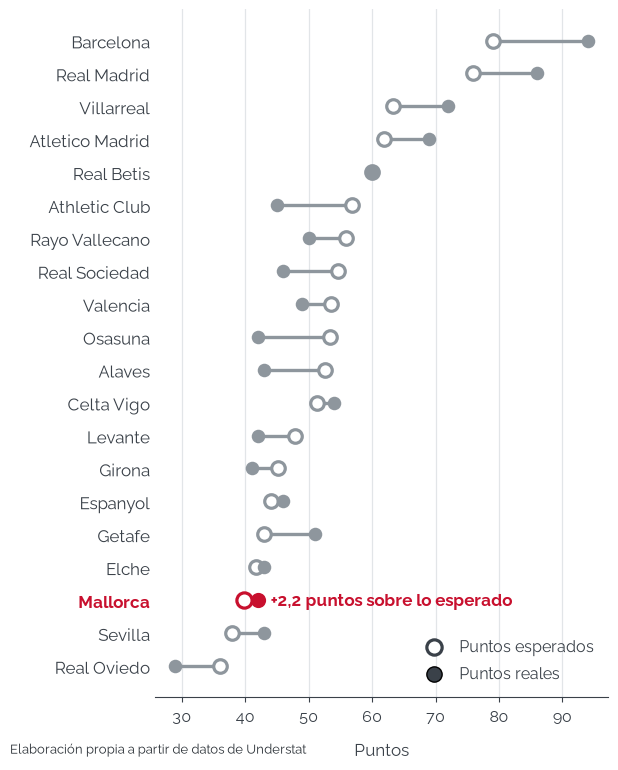

Guardada: images\figura_01_puntos_esperados.png
Hora de guardado: 16:58:07   Tamaño: 251 KB


In [5]:
# === FIGURA 1 · Puntos reales frente a puntos esperados ==================
from pathlib import Path
from datetime import datetime
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

RAIZ = Path.cwd()
if RAIZ.name == "notebooks":
    RAIZ = RAIZ.parent
CARPETA_DATOS = RAIZ / "data"
CARPETA_IMAGENES = RAIZ / "images"

GRIS_TEXTO = "#3A4149"
GRIS_PIE = "#2B3137"
GRIS_MARCA = "#8E969D"

eq = pd.read_csv(CARPETA_DATOS / "equipos_largo_laliga_2526.csv")

tabla = (eq.groupby("equipo")[["points", "expected_points"]].sum()
         .rename(columns={"points": "reales", "expected_points": "esperados"})
         .sort_values("esperados", ascending=False))

fig, ax = plt.subplots(figsize=(ANCHO, 8.0))
fig.subplots_adjust(top=0.97, bottom=0.11, left=0.25, right=0.97)

for i, (equipo, fila) in enumerate(tabla.iterrows()):
    es_mall = equipo.lower() == "mallorca"
    color = COLORES["mallorca"] if es_mall else GRIS_MARCA
    ax.plot([fila["esperados"], fila["reales"]], [i, i],
            color=color, linewidth=3.0 if es_mall else 2.4,
            zorder=2, solid_capstyle="round")
    ax.scatter(fila["esperados"], i, s=120 if es_mall else 95, facecolors="white",
               edgecolors=color, linewidths=2.3, zorder=3)
    ax.scatter(fila["reales"], i, s=120 if es_mall else 95, color=color,
               linewidths=0, zorder=4)

pos = [i for i, e in enumerate(tabla.index) if e.lower() == "mallorca"][0]
fila_m = tabla[tabla.index.str.lower() == "mallorca"].iloc[0]
dif = fila_m["reales"] - fila_m["esperados"]
ax.annotate(f"+{dif:.1f} puntos sobre lo esperado".replace(".", ","),
            xy=(max(fila_m["reales"], fila_m["esperados"]) + 2.0, pos),
            va="center", ha="left", fontsize=12, fontweight="bold",
            color=COLORES["mallorca"], zorder=5)

ax.set_yticks(range(len(tabla)))
ax.set_yticklabels(tabla.index, fontsize=12)
for etiqueta, equipo in zip(ax.get_yticklabels(), tabla.index):
    if equipo.lower() == "mallorca":
        etiqueta.set_color(COLORES["mallorca"])
        etiqueta.set_fontweight("bold")
    else:
        etiqueta.set_color(GRIS_TEXTO)

ax.invert_yaxis()
ax.set_xlabel("Puntos", fontsize=12.5, color=GRIS_TEXTO, labelpad=10)
ax.tick_params(axis="x", colors=GRIS_TEXTO, labelsize=11.5)
ax.tick_params(axis="y", length=0)
ax.grid(axis="x", color="#E2E5E8", linewidth=0.9, zorder=0)
ax.set_axisbelow(True)
ax.spines["left"].set_visible(False)
ax.spines["bottom"].set_color(GRIS_TEXTO)

leyenda = [
    Line2D([0], [0], marker="o", color="none", markerfacecolor="white",
           markeredgecolor=GRIS_TEXTO, markeredgewidth=2.3, markersize=11,
           label="Puntos esperados"),
    Line2D([0], [0], marker="o", color="none", markerfacecolor=GRIS_TEXTO,
           markersize=11, label="Puntos reales"),
]
ax.legend(handles=leyenda, loc="lower right", frameon=False,
          fontsize=11.5, labelcolor=GRIS_TEXTO, handletextpad=0.6)

fig.text(0.02, 0.055, "Elaboración propia a partir de datos de Understat",
         ha="left", va="top", fontsize=9.5, color=GRIS_PIE)

ruta = CARPETA_IMAGENES / "figura_01_puntos_esperados.png"
fig.savefig(ruta)
plt.show()

sello = datetime.fromtimestamp(ruta.stat().st_mtime).strftime("%H:%M:%S")
print(f"Guardada: {ruta.relative_to(RAIZ)}")
print(f"Hora de guardado: {sello}   Tamaño: {ruta.stat().st_size / 1024:.0f} KB")

**Figura 1.** Puntos reales y puntos esperados de los equipos de LaLiga 2025/26. Los equipos aparecen ordenados por puntos esperados. El RCD Mallorca fue decimoctavo en rendimiento esperado y sumó 2,21 puntos más de los que su juego merecía.

*Fuente: elaboración propia a partir de los puntos esperados de Understat (LaLiga 2025/26).*

### Version oscura para el video

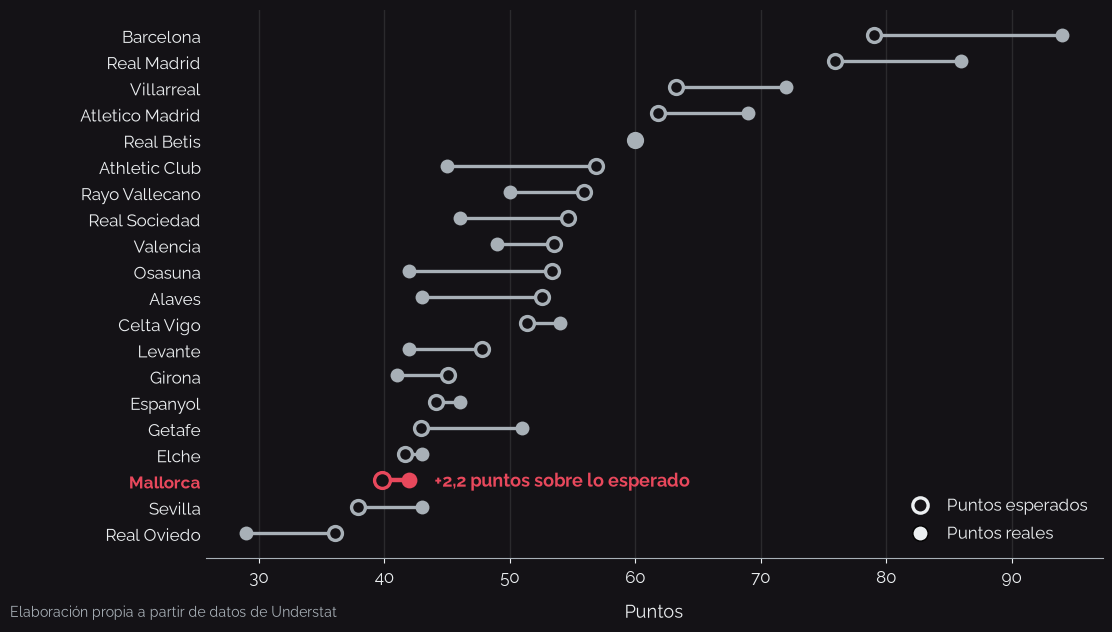

Guardada en: images\figura_01_puntos_esperados_oscura.png


In [6]:
# === FIGURA 1 · versión oscura para el vídeo ============================
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

RAIZ = Path.cwd()
if RAIZ.name == "notebooks":
    RAIZ = RAIZ.parent
CARPETA_DATOS = RAIZ / "data"
CARPETA_IMAGENES = RAIZ / "images"

# paleta para fondo oscuro
CLARO = "#ECEFF1"          # texto principal
CLARO_SUAVE = "#A8B0B7"    # texto secundario y marcadores
ROJO_VIVO = "#E8485C"      # Mallorca, rojo aclarado para que contraste
FONDO_PREVIA = "#141216"   # solo para verlo en el notebook

eq = pd.read_csv(CARPETA_DATOS / "equipos_largo_laliga_2526.csv")

tabla = (eq.groupby("equipo")[["points", "expected_points"]].sum()
         .rename(columns={"points": "reales", "expected_points": "esperados"})
         .sort_values("esperados", ascending=False))

fig, ax = plt.subplots(figsize=(11.5, 6.6))
fig.patch.set_facecolor(FONDO_PREVIA)
ax.set_facecolor(FONDO_PREVIA)
fig.subplots_adjust(top=0.96, bottom=0.13, left=0.19, right=0.97)

for i, (equipo, fila) in enumerate(tabla.iterrows()):
    es_mall = equipo.lower() == "mallorca"
    color = ROJO_VIVO if es_mall else CLARO_SUAVE
    ax.plot([fila["esperados"], fila["reales"]], [i, i],
            color=color, linewidth=3.2 if es_mall else 2.4,
            zorder=2, solid_capstyle="round")
    ax.scatter(fila["esperados"], i, s=130 if es_mall else 100,
               facecolors=FONDO_PREVIA, edgecolors=color, linewidths=2.4, zorder=3)
    ax.scatter(fila["reales"], i, s=130 if es_mall else 100,
               color=color, linewidths=0, zorder=4)

pos = [i for i, e in enumerate(tabla.index) if e.lower() == "mallorca"][0]
fila_m = tabla[tabla.index.str.lower() == "mallorca"].iloc[0]
dif = fila_m["reales"] - fila_m["esperados"]
ax.annotate(f"+{dif:.1f} puntos sobre lo esperado".replace(".", ","),
            xy=(max(fila_m["reales"], fila_m["esperados"]) + 2.0, pos),
            va="center", ha="left", fontsize=13, fontweight="bold",
            color=ROJO_VIVO, zorder=5)

ax.set_yticks(range(len(tabla)))
ax.set_yticklabels(tabla.index, fontsize=12.5)
for etiqueta, equipo in zip(ax.get_yticklabels(), tabla.index):
    if equipo.lower() == "mallorca":
        etiqueta.set_color(ROJO_VIVO)
        etiqueta.set_fontweight("bold")
    else:
        etiqueta.set_color(CLARO)

ax.invert_yaxis()
ax.set_xlabel("Puntos", fontsize=13, color=CLARO, labelpad=10)
ax.tick_params(axis="x", colors=CLARO, labelsize=12)
ax.tick_params(axis="y", length=0)
ax.grid(axis="x", color="#FFFFFF", alpha=0.10, linewidth=1.0, zorder=0)
ax.set_axisbelow(True)
ax.spines["left"].set_visible(False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["bottom"].set_color(CLARO_SUAVE)

leyenda = [
    Line2D([0], [0], marker="o", color="none", markerfacecolor="none",
           markeredgecolor=CLARO, markeredgewidth=2.4, markersize=11,
           label="Puntos esperados"),
    Line2D([0], [0], marker="o", color="none", markerfacecolor=CLARO,
           markersize=11, label="Puntos reales"),
]
ax.legend(handles=leyenda, loc="lower right", frameon=False,
          fontsize=12, labelcolor=CLARO, handletextpad=0.6)

fig.text(0.02, 0.06, "Elaboración propia a partir de datos de Understat",
         ha="left", va="top", fontsize=10, color=CLARO_SUAVE)

ruta = CARPETA_IMAGENES / "figura_01_puntos_esperados_oscura.png"
fig.savefig(ruta, transparent=True, dpi=200)
plt.show()
print("Guardada en:", ruta.relative_to(RAIZ))

## Figura 2 · Altura defensiva

Reparte las acciones defensivas del Mallorca por franjas de altura del campo y las compara con la mediana de la liga. Dibujada sobre medio campo vertical, con la porteria propia abajo.

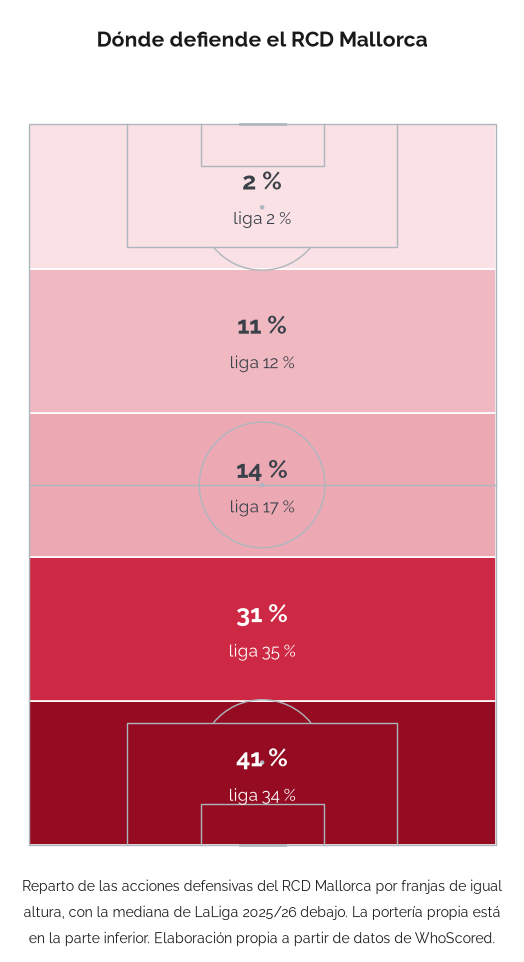

Guardada en: images\figura_02_altura_defensiva.png


In [7]:
# === FIGURA 2 · Altura de las acciones defensivas =======================
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, Normalize
from mplsoccer import VerticalPitch

RAIZ = Path.cwd()
if RAIZ.name == "notebooks":
    RAIZ = RAIZ.parent
CARPETA_IMAGENES = RAIZ / "images"

GRIS_TEXTO = "#3A4149"

# franjas desde la porteria propia (abajo) hasta la rival (arriba)
# (x0, x1, % Mallorca, % mediana de la liga)
FRANJAS = [
    (0, 20, 41, 34),
    (20, 40, 31, 35),
    (40, 60, 14, 17),
    (60, 80, 11, 12),
    (80, 100, 2, 2),
]

mapa = LinearSegmentedColormap.from_list("roja", RAMPA_ROJA)
norma = Normalize(vmin=0, vmax=45)

campo = VerticalPitch(pitch_type="opta", pitch_color="white",
                      line_color="#AEB6BD", linewidth=1.0, line_zorder=3)

fig, ejes = campo.grid(figheight=9.6, title_height=0.09,
                       endnote_height=0.08, grid_height=0.79, axis=False)
ax = ejes["pitch"]

for x0, x1, mall, liga in FRANJAS:
    vertices = [[(x0, 0), (x0, 100), (x1, 100), (x1, 0)]]
    campo.polygon(vertices, ax=ax, facecolor=mapa(norma(mall)),
                  edgecolor="white", linewidth=1.2, zorder=1)
    color_txt = "white" if mall > 27 else GRIS_TEXTO
    cx = (x0 + x1) / 2
    campo.annotate(f"{mall} %", xy=(cx + 2.2, 50), ax=ax, ha="center", va="center",
                   color=color_txt, fontsize=18, fontweight="bold", zorder=4)
    campo.annotate(f"liga {liga} %", xy=(cx - 3.0, 50), ax=ax, ha="center", va="center",
                   color=color_txt, fontsize=12, zorder=4)

ejes["title"].text(0.5, 0.80, "Dónde defiende el RCD Mallorca",
                   ha="center", va="top", fontsize=15, fontweight="bold",
                   color=COLORES["texto"])

ejes["endnote"].text(
    0.5, 1,
    "Reparto de las acciones defensivas del RCD Mallorca por franjas de igual\n"
    "altura, con la mediana de LaLiga 2025/26 debajo. La portería propia está\n"
    "en la parte inferior. Elaboración propia a partir de datos de WhoScored.",
    ha="center", va="top", fontsize=10, color="#1A1A1A", linespacing=1.6)

ruta = CARPETA_IMAGENES / "figura_02_altura_defensiva.png"
fig.savefig(ruta)
plt.show()
print("Guardada en:", ruta.relative_to(RAIZ))

**Figura 2.** Reparto de las acciones defensivas del RCD Mallorca por franjas de igual altura, con la mediana de LaLiga debajo. La portería propia está abajo. El 41 % de sus acciones defensivas se produjo en la quinta parte más cercana a su propia portería, siete puntos por encima de la mediana: ningún equipo de la competición defendía tan bajo.

*Fuente: elaboración propia a partir de los eventos Opta de WhoScored.*

### Version oscura para el video

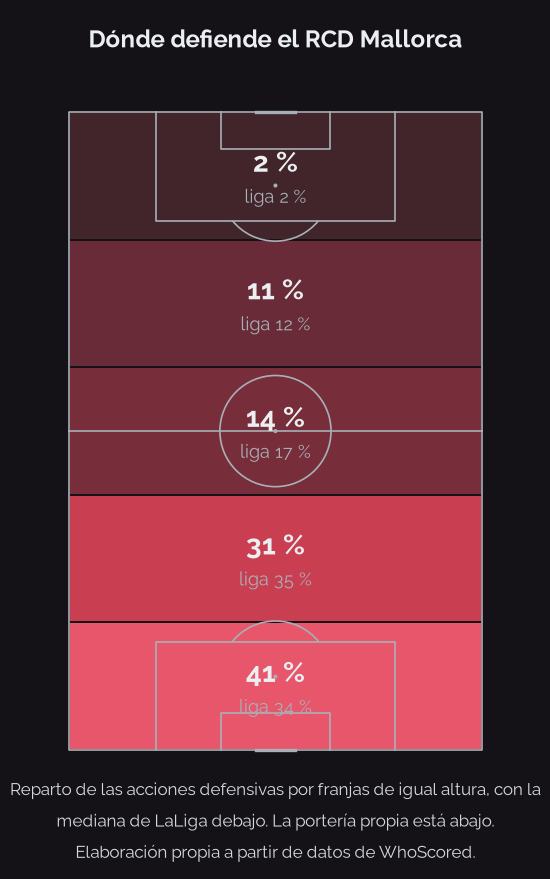

Guardada en: images\figura_02_altura_defensiva_oscura.png


In [8]:
# === FIGURA 2 · versión oscura para el vídeo ============================
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, Normalize
from mplsoccer import VerticalPitch

RAIZ = Path.cwd()
if RAIZ.name == "notebooks":
    RAIZ = RAIZ.parent
CARPETA_IMAGENES = RAIZ / "images"

CLARO = "#ECEFF1"
CLARO_SUAVE = "#A8B0B7"
FONDO_PREVIA = "#141216"
RAMPA_OSCURA = ["#3A2328", "#6B2B38", "#A33446", "#D64156", "#F26176"]

FRANJAS = [
    (0, 20, 41, 34),
    (20, 40, 31, 35),
    (40, 60, 14, 17),
    (60, 80, 11, 12),
    (80, 100, 2, 2),
]

mapa = LinearSegmentedColormap.from_list("roja_oscura", RAMPA_OSCURA)
norma = Normalize(vmin=0, vmax=45)

campo = VerticalPitch(pitch_type="opta", pitch_color="none",
                      line_color=CLARO_SUAVE, linewidth=1.2, line_zorder=3)

fig, ejes = campo.grid(figheight=8.6, title_height=0.09,
                       endnote_height=0.09, grid_height=0.78, axis=False)
fig.patch.set_facecolor(FONDO_PREVIA)
ax = ejes["pitch"]
ax.set_facecolor(FONDO_PREVIA)

for x0, x1, mall, liga in FRANJAS:
    vertices = [[(x0, 0), (x0, 100), (x1, 100), (x1, 0)]]
    campo.polygon(vertices, ax=ax, facecolor=mapa(norma(mall)),
                  edgecolor=FONDO_PREVIA, linewidth=1.4, zorder=1)
    cx = (x0 + x1) / 2
    campo.annotate(f"{mall} %", xy=(cx + 2.2, 50), ax=ax, ha="center", va="center",
                   color=CLARO, fontsize=20, fontweight="bold", zorder=4)
    campo.annotate(f"liga {liga} %", xy=(cx - 3.2, 50), ax=ax, ha="center", va="center",
                   color=CLARO_SUAVE, fontsize=13, zorder=4)

ejes["title"].text(0.5, 0.80, "Dónde defiende el RCD Mallorca",
                   ha="center", va="top", fontsize=17, fontweight="bold", color=CLARO)

ejes["endnote"].text(
    0.5, 1,
    "Reparto de las acciones defensivas por franjas de igual altura, con la\n"
    "mediana de LaLiga debajo. La portería propia está abajo.\n"
    "Elaboración propia a partir de datos de WhoScored.",
    ha="center", va="top", fontsize=12, color="#D5DADE", linespacing=1.6)

ruta = CARPETA_IMAGENES / "figura_02_altura_defensiva_oscura.png"
fig.savefig(ruta, transparent=True, dpi=200)
plt.show()
print("Guardada en:", ruta.relative_to(RAIZ))

## Figura 3 · Origen de las ocasiones

Mide que parte de las ocasiones de cada equipo nace de un centro al area, tomando los pases clave marcados por Opta y mirando cuales llevan el calificador de centro.

Pases clave: 285
De centro: 116  (40.7 %)
Desde campo contrario: 276   desde campo propio: 9


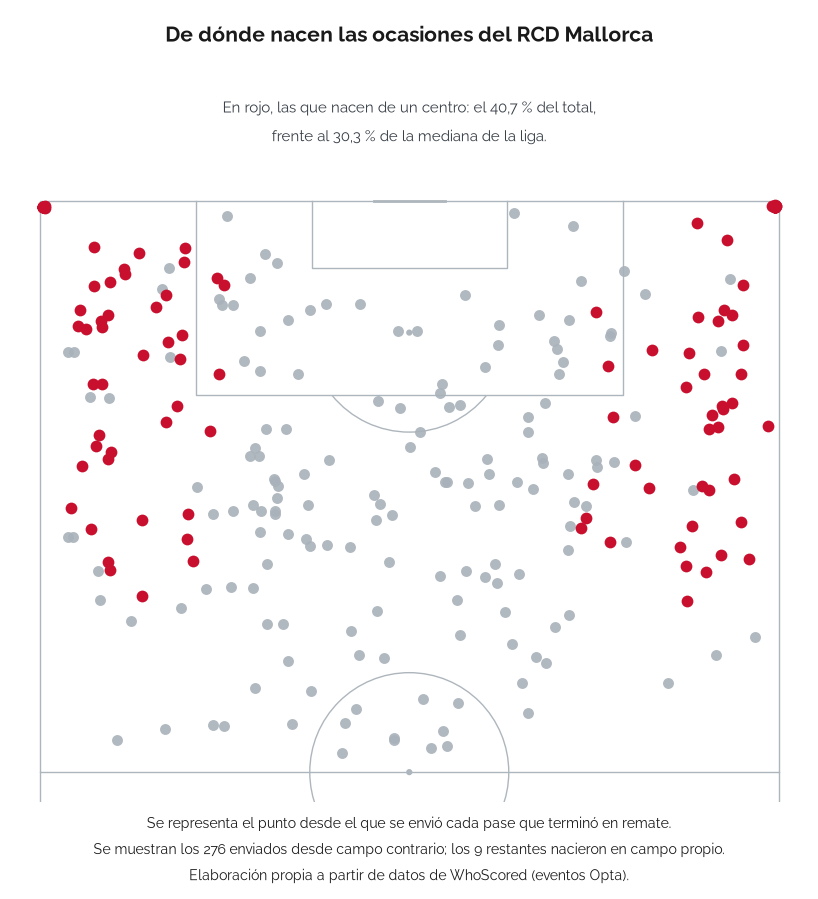

Guardada en: images\figura_03_origen_ocasiones.png


In [9]:
# === FIGURA 3 · Origen de los pases que generan remate ==================
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from mplsoccer import VerticalPitch

RAIZ = Path.cwd()
if RAIZ.name == "notebooks":
    RAIZ = RAIZ.parent
CARPETA_DATOS = RAIZ / "data"
CARPETA_IMAGENES = RAIZ / "images"

GRIS_PUNTO = "#A9B2BA"

ev = pd.read_parquet(CARPETA_DATOS / "eventos_laliga_2526.parquet")

pases = ev[(ev["type"] == "Pass") & (ev["team"] == "Mallorca")].copy()
pases["q"] = pases["qualifiers"].astype(str)
clave = pases[pases["q"].str.contains("KeyPass", na=False)].copy()
clave["centro"] = clave["q"].str.contains("Cross", na=False)

total = len(clave)
centros = int(clave["centro"].sum())
contrario = clave[clave["x"] >= 50]
propio = total - len(contrario)

print(f"Pases clave: {total}")
print(f"De centro: {centros}  ({centros / total * 100:.1f} %)")
print(f"Desde campo contrario: {len(contrario)}   desde campo propio: {propio}")

campo = VerticalPitch(pitch_type="opta", half=True, pitch_color="white",
                      line_color="#AEB6BD", linewidth=1.0, line_zorder=1)

fig, ejes = campo.grid(figheight=9.0, title_height=0.17,
                       endnote_height=0.07, grid_height=0.70, axis=False)
ax = ejes["pitch"]

otros = contrario[~contrario["centro"]]
cruces = contrario[contrario["centro"]]

campo.scatter(otros["x"], otros["y"], ax=ax, s=62, color=GRIS_PUNTO,
              linewidths=0, alpha=0.9, zorder=2)
campo.scatter(cruces["x"], cruces["y"], ax=ax, s=72, color=COLORES["mallorca"],
              linewidths=0, zorder=3)

ejes["title"].text(0.5, 0.92, "De dónde nacen las ocasiones del RCD Mallorca",
                   ha="center", va="top", fontsize=15, fontweight="bold",
                   color=COLORES["texto"])
ejes["title"].text(0.5, 0.45,
                   "En rojo, las que nacen de un centro: el 40,7 % del total,\n"
                   "frente al 30,3 % de la mediana de la liga.",
                   ha="center", va="top", fontsize=11, color="#3A4149",
                   linespacing=1.6)

ejes["endnote"].text(
    0.5, 1,
    "Se representa el punto desde el que se envió cada pase que terminó en remate.\n"
    f"Se muestran los {len(contrario)} enviados desde campo contrario; los {propio} restantes nacieron en campo propio.\n"
    "Elaboración propia a partir de datos de WhoScored (eventos Opta).",
    ha="center", va="top", fontsize=10, color="#1A1A1A", linespacing=1.6)

ruta = CARPETA_IMAGENES / "figura_03_origen_ocasiones.png"
fig.savefig(ruta)
plt.show()
print("Guardada en:", ruta.relative_to(RAIZ))

**Figura 3.** Porcentaje de ocasiones que nacen de un centro en cada equipo de LaLiga 2025/26. El 40,7 % de las del RCD Mallorca venían de un centro, frente al 30,3 % de la mediana de la liga; solo Osasuna y Getafe dependían más del centro. Con 285 pases clave en toda la temporada es además el tercer registro más bajo de la competición.

*Fuente: elaboración propia a partir de los eventos Opta de WhoScored.*

### Version oscura para el video

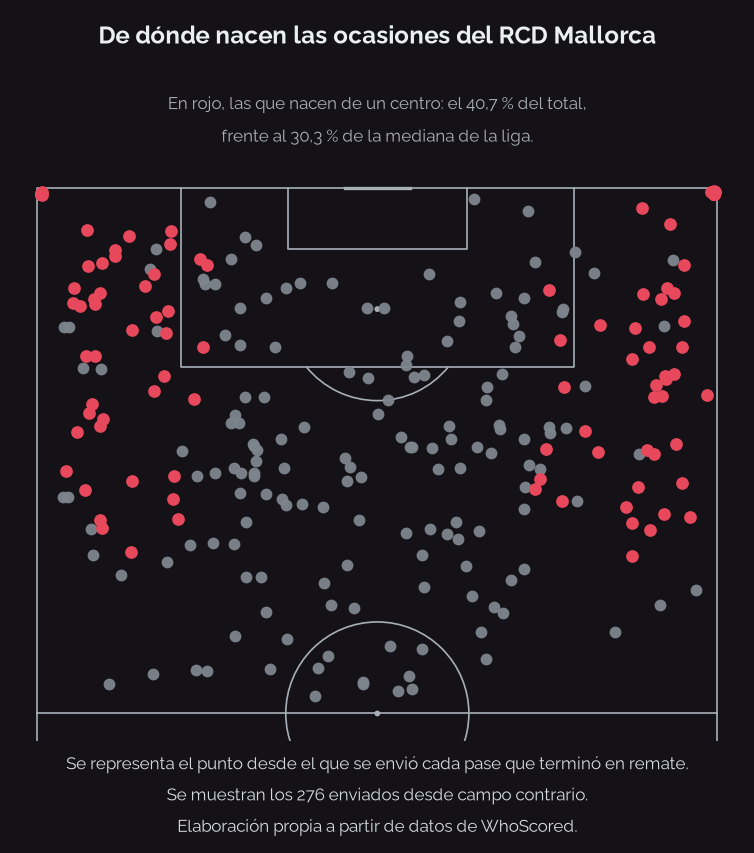

Guardada en: images\figura_03_origen_ocasiones_oscura.png


In [10]:
# === FIGURA 3 · versión oscura para el vídeo ============================
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from mplsoccer import VerticalPitch

RAIZ = Path.cwd()
if RAIZ.name == "notebooks":
    RAIZ = RAIZ.parent
CARPETA_DATOS = RAIZ / "data"
CARPETA_IMAGENES = RAIZ / "images"

CLARO = "#ECEFF1"
CLARO_SUAVE = "#A8B0B7"
GRIS_PUNTO = "#7E868D"
ROJO_VIVO = "#E8485C"
FONDO_PREVIA = "#141216"

ev = pd.read_parquet(CARPETA_DATOS / "eventos_laliga_2526.parquet")

pases = ev[(ev["type"] == "Pass") & (ev["team"] == "Mallorca")].copy()
pases["q"] = pases["qualifiers"].astype(str)
clave = pases[pases["q"].str.contains("KeyPass", na=False)].copy()
clave["centro"] = clave["q"].str.contains("Cross", na=False)

contrario = clave[clave["x"] >= 50]
propio = len(clave) - len(contrario)

campo = VerticalPitch(pitch_type="opta", half=True, pitch_color="none",
                      line_color=CLARO_SUAVE, linewidth=1.2, line_zorder=1)

fig, ejes = campo.grid(figheight=8.4, title_height=0.17,
                       endnote_height=0.08, grid_height=0.69, axis=False)
fig.patch.set_facecolor(FONDO_PREVIA)
ax = ejes["pitch"]
ax.set_facecolor(FONDO_PREVIA)

otros = contrario[~contrario["centro"]]
cruces = contrario[contrario["centro"]]

campo.scatter(otros["x"], otros["y"], ax=ax, s=72, color=GRIS_PUNTO,
              linewidths=0, alpha=0.95, zorder=2)
campo.scatter(cruces["x"], cruces["y"], ax=ax, s=84, color=ROJO_VIVO,
              linewidths=0, zorder=3)

ejes["title"].text(0.5, 0.92, "De dónde nacen las ocasiones del RCD Mallorca",
                   ha="center", va="top", fontsize=17, fontweight="bold", color=CLARO)
ejes["title"].text(0.5, 0.45,
                   "En rojo, las que nacen de un centro: el 40,7 % del total,\n"
                   "frente al 30,3 % de la mediana de la liga.",
                   ha="center", va="top", fontsize=12.5, color=CLARO_SUAVE,
                   linespacing=1.6)

ejes["endnote"].text(
    0.5, 1,
    "Se representa el punto desde el que se envió cada pase que terminó en remate.\n"
    f"Se muestran los {len(contrario)} enviados desde campo contrario.\n"
    "Elaboración propia a partir de datos de WhoScored.",
    ha="center", va="top", fontsize=12, color="#D5DADE", linespacing=1.6)

ruta = CARPETA_IMAGENES / "figura_03_origen_ocasiones_oscura.png"
fig.savefig(ruta, transparent=True, dpi=200)
plt.show()
print("Guardada en:", ruta.relative_to(RAIZ))

## Figura 4 · Lo que si funcionaba

Perfil de los tres jugadores del Mallorca que rendian por encima de su puesto. Sirve para delimitar que no debe tocar el refuerzo.

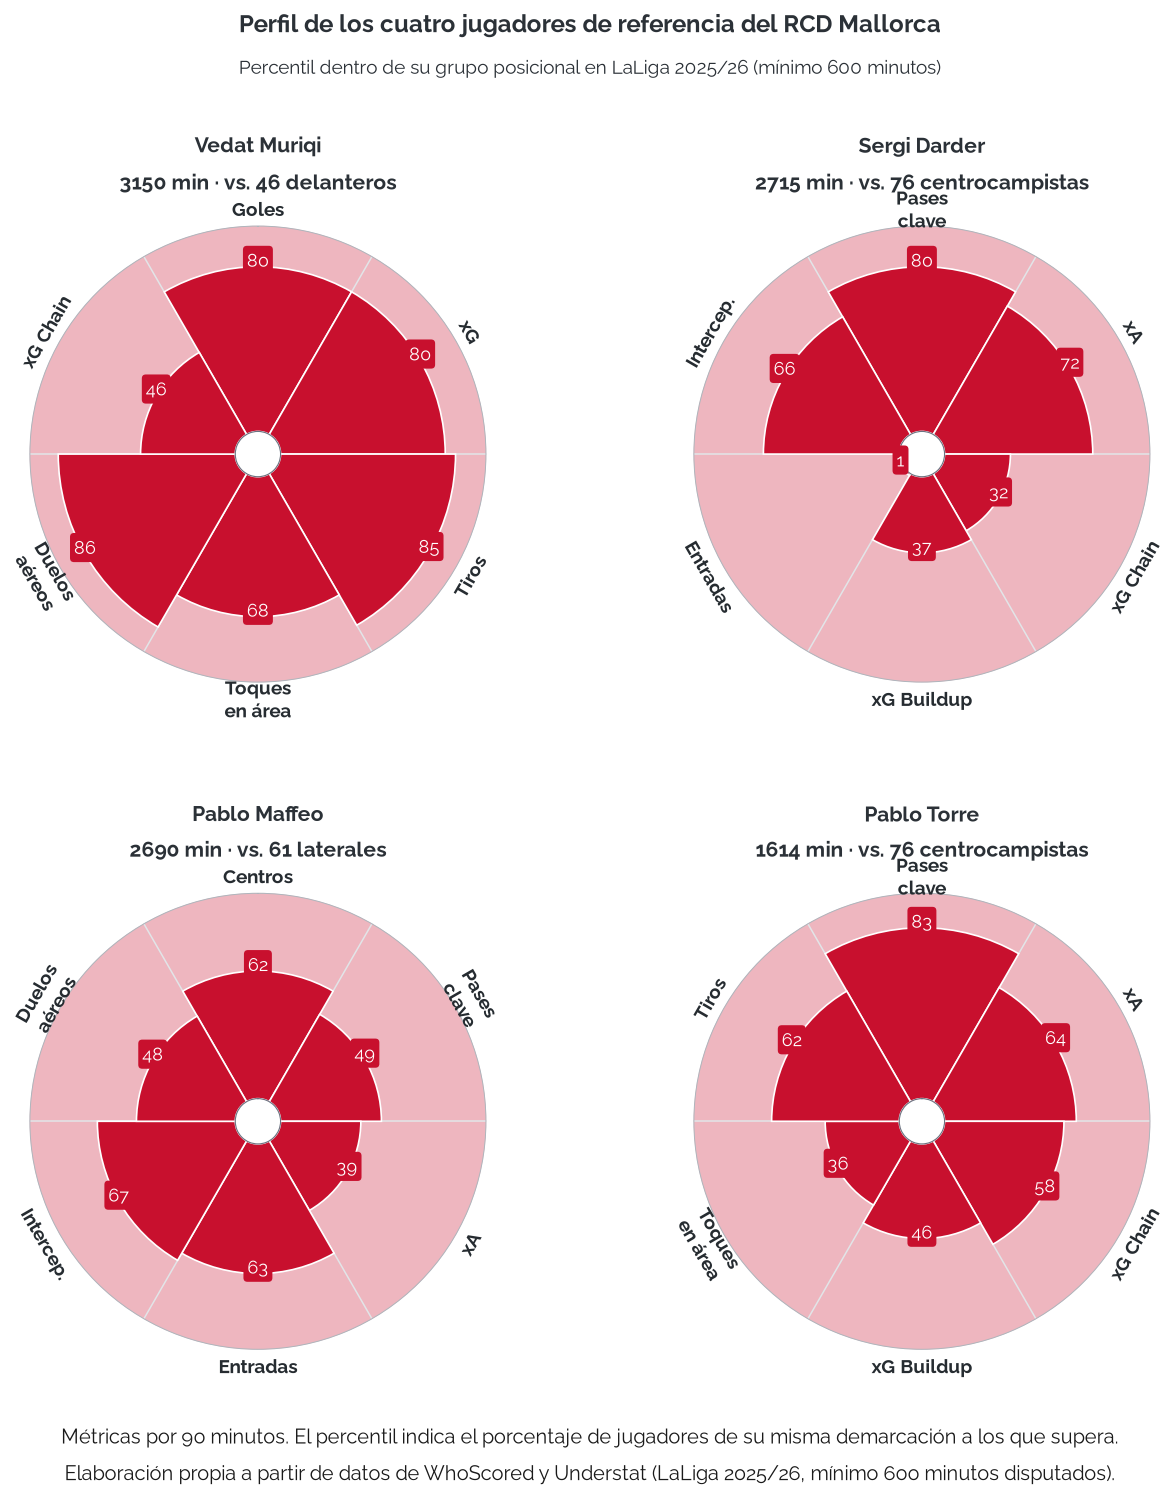

COMPROBACION DE PERCENTILES

Vedat Muriqi  (3150 min, grupo de 46)
   Goles            goals_90           p80
   xG               xg_90              p80
   Tiros            shots_90           p85
   Toques en área   toques_area_90     p68
   Duelos aéreos    Aerial_90          p86
   xG Chain         xg_chain_90        p46

Sergi Darder  (2715 min, grupo de 76)
   Pases clave      key_passes_90      p80
   xA               xa_90              p72
   xG Chain         xg_chain_90        p32
   xG Buildup       xg_buildup_90      p37
   Entradas         Tackle_90          p1
   Intercep.        Interception_90    p66

Pablo Maffeo  (2690 min, grupo de 61)
   Centros          centros_90         p62
   Pases clave      key_passes_90      p49
   xA               xa_90              p39
   Entradas         Tackle_90          p63
   Intercep.        Interception_90    p67
   Duelos aéreos    Aerial_90          p48

Pablo Torre  (1614 min, grupo de 76)
   Pases clave      key_passes_90      p83
 

In [11]:
# ============================================================
# FIGURA 4 - PERFILES INDIVIDUALES (VERSION DOCUMENTO)
# Notebook: 05_visualizaciones.ipynb
# Sustituye por completo a la celda que generaba figura_04_perfiles.png
# ============================================================
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mplsoccer import PyPizza

# Detecta si el notebook corre desde la raiz del proyecto o desde notebooks/
BASE = ".." if os.path.isdir("../data") else "."
DATOS  = os.path.join(BASE, "data")
IMAGES = os.path.join(BASE, "images")

GRIS_TITULO = "#2B3137"
GRIS_TEXTO  = "#262C31"
GRIS_PIE    = "#1A1A1A"
GRIS_LINEA  = "#E2E5E8"
GRIS_BORDE  = "#AEB6BD"
ROJO        = "#C8102E"

MIN_MINUTOS = 600
RUTA = os.path.join(IMAGES, "figura_04_perfiles.png")

met = pd.read_csv(os.path.join(DATOS, "metricas_jugadores_laliga_2526.csv"))

# ---------- definicion de los cuatro perfiles ----------
PERFILES = [
    {"jugador": "Vedat Muriqi",
     "grupos":  ["delantero"],
     "etiqueta_grupo": "delanteros",
     "metricas": [("goals_90", "Goles"), ("xg_90", "xG"), ("shots_90", "Tiros"),
                  ("toques_area_90", "Toques\nen área"), ("Aerial_90", "Duelos\naéreos"),
                  ("xg_chain_90", "xG Chain")]},
    {"jugador": "Sergi Darder",
     "grupos":  ["mediocentro", "mediapunta"],
     "etiqueta_grupo": "centrocampistas",
     "metricas": [("key_passes_90", "Pases\nclave"), ("xa_90", "xA"),
                  ("xg_chain_90", "xG Chain"), ("xg_buildup_90", "xG Buildup"),
                  ("Tackle_90", "Entradas"), ("Interception_90", "Intercep.")]},
    {"jugador": "Pablo Maffeo",
     "grupos":  ["lateral"],
     "etiqueta_grupo": "laterales",
     "metricas": [("centros_90", "Centros"), ("key_passes_90", "Pases\nclave"),
                  ("xa_90", "xA"), ("Tackle_90", "Entradas"),
                  ("Interception_90", "Intercep."), ("Aerial_90", "Duelos\naéreos")]},
    {"jugador": "Pablo Torre",
     "grupos":  ["mediocentro", "mediapunta"],
     "etiqueta_grupo": "centrocampistas",
     "metricas": [("key_passes_90", "Pases\nclave"), ("xa_90", "xA"),
                  ("xg_chain_90", "xG Chain"), ("xg_buildup_90", "xG Buildup"),
                  ("toques_area_90", "Toques\nen área"), ("shots_90", "Tiros")]},
]

def grupo_de(df, claves):
    pos = df["posicion"].astype(str).str.lower()
    m = pd.Series(False, index=df.index)
    for c in claves:
        m = m | pos.str.contains(c, na=False)
    return df[m & (df["minutes"] >= MIN_MINUTOS)]

def percentil(serie, valor):
    s = serie.dropna()
    return int(round((s < valor).mean() * 100))

# ---------- figura ----------
fig, ejes = plt.subplots(2, 2, figsize=(13.8, 15.4),
                         subplot_kw={"projection": "polar"})
fig.patch.set_facecolor("white")

for ax, perfil in zip(ejes.ravel(), PERFILES):
    fila = met[met["jugador"].astype(str).str.lower() == perfil["jugador"].lower()]
    if len(fila) == 0:
        raise ValueError(f"No encuentro a {perfil['jugador']} en el CSV")
    fila = fila.iloc[0]

    comparables = grupo_de(met, perfil["grupos"])
    nombres = [n for _, n in perfil["metricas"]]
    valores = [percentil(comparables[c], fila[c]) for c, _ in perfil["metricas"]]
    perfil["_valores"] = valores
    perfil["_n"] = len(comparables)
    perfil["_min"] = fila["minutes"]

    baker = PyPizza(
        params=nombres,
        background_color="white",
        straight_line_color=GRIS_LINEA, straight_line_lw=1.1,
        last_circle_color=GRIS_BORDE,   last_circle_lw=1.4,
        other_circle_lw=0, inner_circle_size=11,
    )
    baker.make_pizza(
        valores, ax=ax,
        color_blank_space="same", blank_alpha=0.30,
        kwargs_slices=dict(facecolor=ROJO, edgecolor="white", linewidth=1.2, zorder=2),
        kwargs_params=dict(color=GRIS_TEXTO, fontsize=14, fontweight="bold", va="center"),
        kwargs_values=dict(color="white", fontsize=13, zorder=3,
                           bbox=dict(edgecolor="none", facecolor=ROJO,
                                     boxstyle="round,pad=0.22", lw=1)),
    )
    ax.set_title(f"{perfil['jugador']}\n{int(fila['minutes'])} min · vs. {perfil['_n']} {perfil['etiqueta_grupo']}",
                 fontsize=15, fontweight="bold", color=GRIS_TITULO,
                 pad=26, linespacing=1.5)

fig.text(0.5, 0.985, "Perfil de los cuatro jugadores de referencia del RCD Mallorca",
         ha="center", va="top", fontsize=17, fontweight="bold", color=GRIS_TITULO)
fig.text(0.5, 0.955, "Percentil dentro de su grupo posicional en LaLiga 2025/26 (mínimo 600 minutos)",
         ha="center", va="top", fontsize=13.5, color=GRIS_TITULO)

fig.text(0.5, 0.022,
         "Métricas por 90 minutos. El percentil indica el porcentaje de jugadores de su misma demarcación a los que supera.\n"
         "Elaboración propia a partir de datos de WhoScored y Understat (LaLiga 2025/26, mínimo 600 minutos disputados).",
         ha="center", va="bottom", fontsize=14.5, color=GRIS_PIE, linespacing=1.55)

plt.subplots_adjust(top=0.845, bottom=0.115, left=0.09, right=0.91,
                    hspace=0.46, wspace=0.42)

fig.savefig(RUTA, dpi=200, facecolor="white")
plt.show()

# ---------- control ----------
print("COMPROBACION DE PERCENTILES")
for p in PERFILES:
    print(f"\n{p['jugador']}  ({int(p['_min'])} min, grupo de {p['_n']})")
    for (c, n), v in zip(p["metricas"], p["_valores"]):
        print(f"   {n.replace(chr(10),' '):<16} {c:<18} p{v}")
print("\nArchivo:", os.path.relpath(RUTA))
print("Modificado:", time.ctime(os.path.getmtime(RUTA)),
      "|", round(os.path.getsize(RUTA)/1024), "KB")

**Figura 4.** Percentiles de Muriqi, Darder y Maffeo dentro de su propio grupo de posición en LaLiga 2025/26. Muriqi está en el percentil 86 en juego aéreo, Darder en el 80 en pases clave y Maffeo en el 67 en intercepciones. Tocar cualquiera de esas tres piezas habría resuelto un problema que el equipo no tenía.

*Fuente: elaboración propia a partir de Understat y los eventos Opta de WhoScored.*

### Version oscura para el video

Vedat Muriqi [80, 80, 85, 68, 86, 46]
Sergi Darder [80, 72, 32, 37, 1, 66]
Pablo Maffeo [62, 49, 39, 63, 67, 48]
Pablo Torre [83, 64, 58, 46, 36, 62]


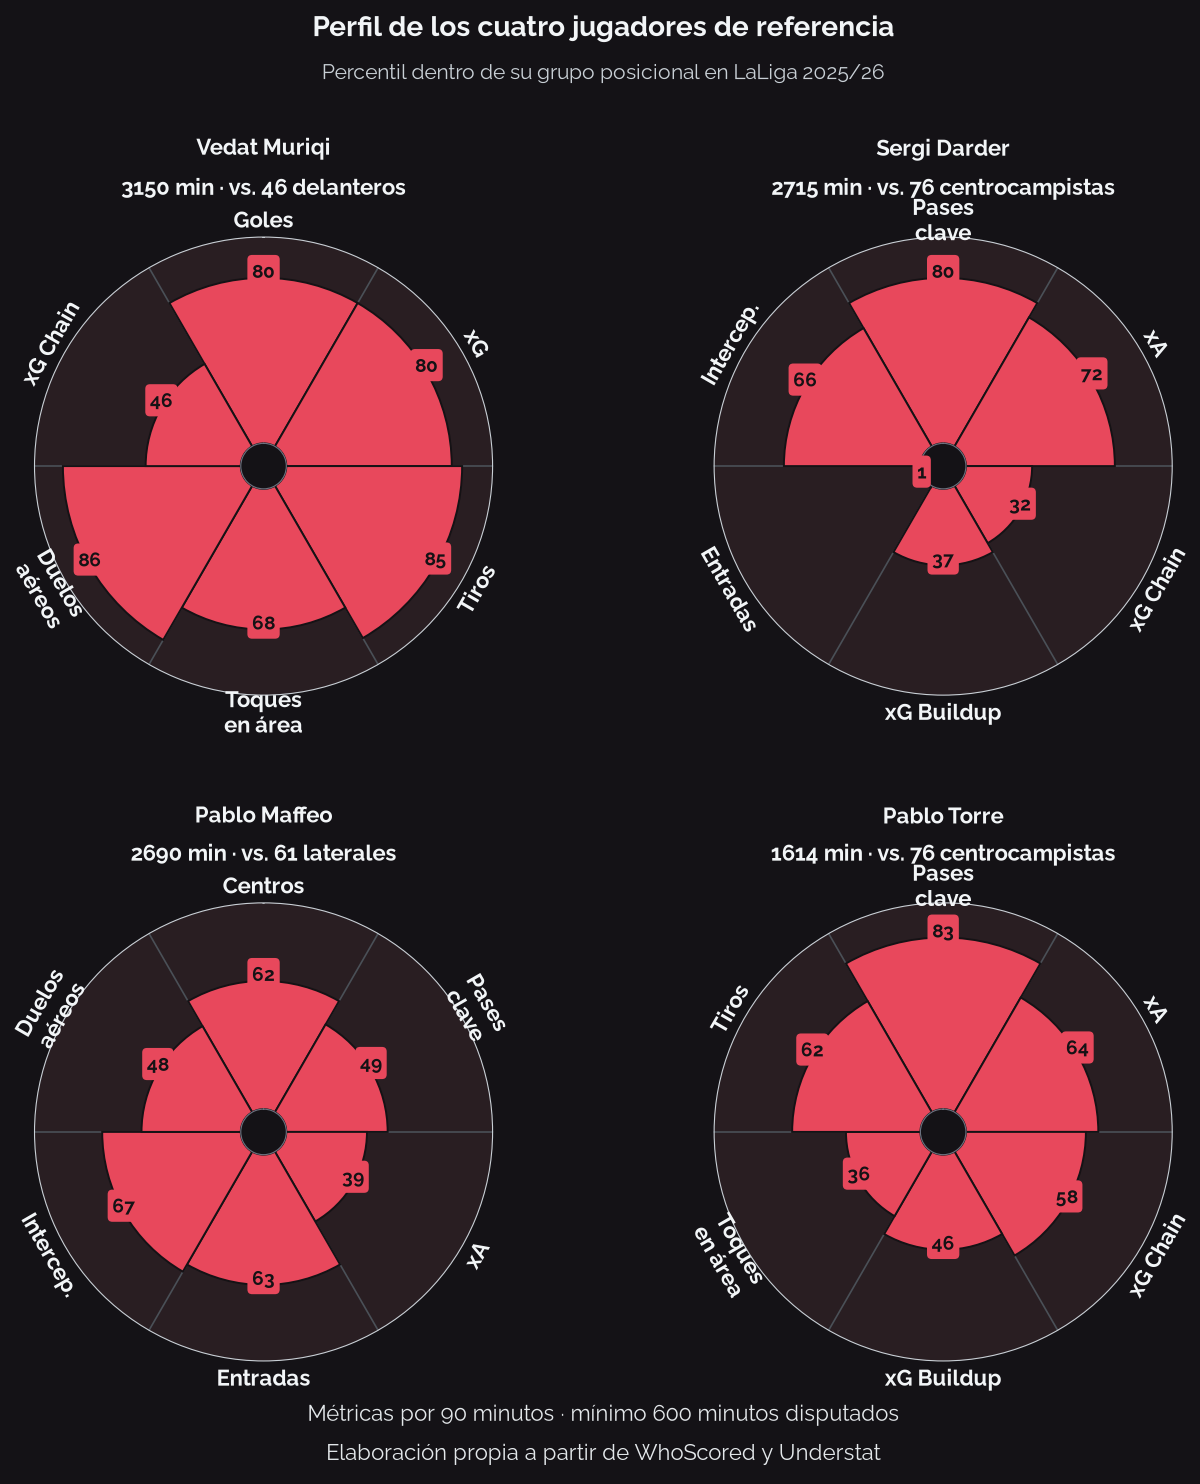


Archivo: images\figura_04_perfiles_oscura.png
Modificado: Tue Nov 10 16:58:38 2026 | 660 KB


In [12]:
# ============================================================
# FIGURA 4 - VERSION OSCURA PARA SLIDE DEL VIDEO
# Notebook: 05_visualizaciones.ipynb — se puede ejecutar sola
# ============================================================
import os, time
import pandas as pd
import matplotlib.pyplot as plt
from mplsoccer import PyPizza

BASE = ".." if os.path.isdir("../data") else "."
DATOS  = os.path.join(BASE, "data")
IMAGES = os.path.join(BASE, "images")

CLARO        = "#F2F5F7"
CLARO_SUAVE  = "#C8CFD5"
ROJO_VIVO    = "#E8485C"
VACIO_OSC    = "#3E2A2F"     # relleno de la parte no alcanzada
FONDO_PREVIA = "#141216"
LINEA_OSC    = "#4A5057"

MIN_MINUTOS = 600
RUTA_OSC = os.path.join(IMAGES, "figura_04_perfiles_oscura.png")

met = pd.read_csv(os.path.join(DATOS, "metricas_jugadores_laliga_2526.csv"))

PERFILES = [
    {"jugador": "Vedat Muriqi",
     "grupos":  ["delantero"],
     "etiqueta_grupo": "delanteros",
     "metricas": [("goals_90", "Goles"), ("xg_90", "xG"), ("shots_90", "Tiros"),
                  ("toques_area_90", "Toques\nen área"), ("Aerial_90", "Duelos\naéreos"),
                  ("xg_chain_90", "xG Chain")]},
    {"jugador": "Sergi Darder",
     "grupos":  ["mediocentro", "mediapunta"],
     "etiqueta_grupo": "centrocampistas",
     "metricas": [("key_passes_90", "Pases\nclave"), ("xa_90", "xA"),
                  ("xg_chain_90", "xG Chain"), ("xg_buildup_90", "xG Buildup"),
                  ("Tackle_90", "Entradas"), ("Interception_90", "Intercep.")]},
    {"jugador": "Pablo Maffeo",
     "grupos":  ["lateral"],
     "etiqueta_grupo": "laterales",
     "metricas": [("centros_90", "Centros"), ("key_passes_90", "Pases\nclave"),
                  ("xa_90", "xA"), ("Tackle_90", "Entradas"),
                  ("Interception_90", "Intercep."), ("Aerial_90", "Duelos\naéreos")]},
    {"jugador": "Pablo Torre",
     "grupos":  ["mediocentro", "mediapunta"],
     "etiqueta_grupo": "centrocampistas",
     "metricas": [("key_passes_90", "Pases\nclave"), ("xa_90", "xA"),
                  ("xg_chain_90", "xG Chain"), ("xg_buildup_90", "xG Buildup"),
                  ("toques_area_90", "Toques\nen área"), ("shots_90", "Tiros")]},
]

def grupo_de(df, claves):
    pos = df["posicion"].astype(str).str.lower()
    m = pd.Series(False, index=df.index)
    for c in claves:
        m = m | pos.str.contains(c, na=False)
    return df[m & (df["minutes"] >= MIN_MINUTOS)]

def percentil(serie, valor):
    s = serie.dropna()
    return int(round((s < valor).mean() * 100))

for perfil in PERFILES:
    fila = met[met["jugador"].astype(str).str.lower() == perfil["jugador"].lower()].iloc[0]
    comparables = grupo_de(met, perfil["grupos"])
    perfil["_valores"] = [percentil(comparables[c], fila[c]) for c, _ in perfil["metricas"]]
    perfil["_n"] = len(comparables)
    perfil["_min"] = fila["minutes"]
    print(perfil["jugador"], perfil["_valores"])

# ---------- figura ----------
fig, ejes = plt.subplots(2, 2, figsize=(13.8, 15.0),
                         subplot_kw={"projection": "polar"})
fig.patch.set_facecolor(FONDO_PREVIA)   # solo para verla aqui

for ax, perfil in zip(ejes.ravel(), PERFILES):
    nombres = [n for _, n in perfil["metricas"]]
    valores = perfil["_valores"]

    baker = PyPizza(
        params=nombres,
        background_color=FONDO_PREVIA,
        straight_line_color=LINEA_OSC, straight_line_lw=1.2,
        last_circle_color=CLARO_SUAVE,  last_circle_lw=1.6,
        other_circle_lw=0, inner_circle_size=11,
    )
    baker.make_pizza(
        valores, ax=ax,
        color_blank_space=[VACIO_OSC] * len(nombres),
        kwargs_slices=dict(facecolor=ROJO_VIVO, edgecolor="#151215",
                           linewidth=1.4, zorder=2),
        kwargs_params=dict(color=CLARO, fontsize=15.5, fontweight="bold", va="center"),
        kwargs_values=dict(color="#151215", fontsize=14, fontweight="bold", zorder=3,
                           bbox=dict(edgecolor="none", facecolor=ROJO_VIVO,
                                     boxstyle="round,pad=0.24", lw=1)),
    )
    ax.patch.set_alpha(0)
    ax.set_title(f"{perfil['jugador']}\n{int(perfil['_min'])} min · vs. {perfil['_n']} {perfil['etiqueta_grupo']}",
                 fontsize=16, fontweight="bold", color=CLARO,
                 pad=30, linespacing=1.5)

fig.text(0.5, 0.996, "Perfil de los cuatro jugadores de referencia",
         ha="center", va="top", fontsize=20, fontweight="bold", color=CLARO)
fig.text(0.5, 0.963, "Percentil dentro de su grupo posicional en LaLiga 2025/26",
         ha="center", va="top", fontsize=15, color=CLARO_SUAVE)
fig.text(0.5, 0.020,
         "Métricas por 90 minutos · mínimo 600 minutos disputados\n"
         "Elaboración propia a partir de WhoScored y Understat",
         ha="center", va="bottom", fontsize=15.5, color="#E3E7EA", linespacing=1.55)

plt.subplots_adjust(top=0.845, bottom=0.095, left=0.07, right=0.93,
                    hspace=0.45, wspace=0.34)

fig.savefig(RUTA_OSC, dpi=200, transparent=True)
plt.show()

print("\nArchivo:", os.path.relpath(RUTA_OSC))
print("Modificado:", time.ctime(os.path.getmtime(RUTA_OSC)),
      "|", round(os.path.getsize(RUTA_OSC)/1024), "KB")

## Figura 5 · Zonas donde concedia

Reparte los goles esperados que el Mallorca concedia en juego en curso por zonas de su propio campo, y los compara con la mediana de los veinte equipos. Todas las comparaciones usan la mediana, nunca la media.

Guardare la figura en: figura_05_zonas_concedidas.png


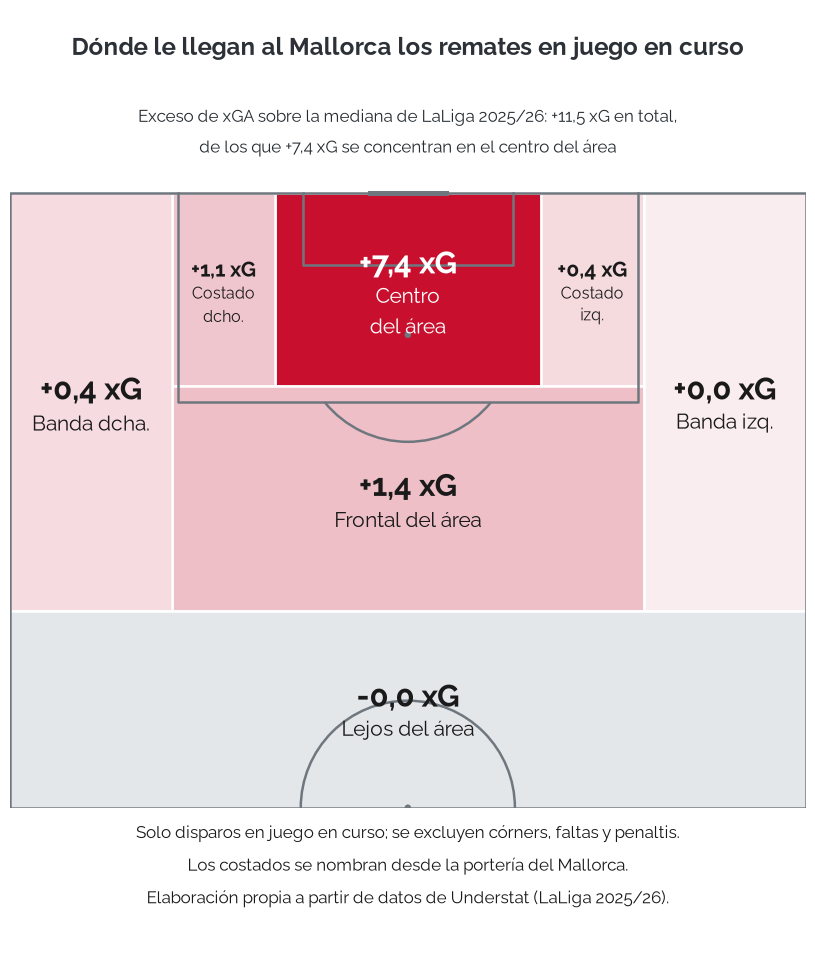


CIFRAS PARA EL APARTADO 3.4 (todas sobre la MEDIANA)
Juego abierto, Mallorca: 49.51 | mediana: 37.99 | exceso: +11.52
Centro del area: 38.59 | mediana: 31.20 | exceso: +7.39 (64 % del total)
Bandas del area: 4.75 | mediana: 3.36 | exceso: +1.39 (12 % del total) | exceso relativo: 41.3 %
Puesto del Mallorca en xGA concedida por las bandas del area: 1 de 20

TODAS LAS ZONAS
  Banda dcha.             0.37     0.01    +0.36
  Banda izq.              0.02     0.00    +0.02
  Centro del área        38.59    31.20    +7.39
  Costado dcho.           2.67     1.57    +1.10
  Costado izq.            2.07     1.65    +0.42
  Frontal del área        5.75     4.39    +1.36
  Lejos del área          0.03     0.03    -0.00

Archivo: images\figura_05_zonas_concedidas.png
Modificado: Tue Nov 10 16:58:40 2026 | 194 KB


In [13]:
# ============================================================
# FIGURA 5 - EXCESO DE xGA POR ZONA EN JUEGO EN CURSO (VERSION DOCUMENTO)
# Notebook: 05_visualizaciones.ipynb
# Calculado sobre la MEDIANA de la liga, zonificacion del apartado 3.4
# ============================================================
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from mplsoccer import VerticalPitch

BASE = ".." if os.path.isdir("../data") else "."
DATOS  = os.path.join(BASE, "data")
IMAGES = os.path.join(BASE, "images")

GRIS_TITULO = "#2B3137"
GRIS_TEXTO  = "#262C31"
GRIS_PIE    = "#1A1A1A"
GRIS_LINEA  = "#6F777E"

candidatos = [f for f in os.listdir(IMAGES)
              if f.startswith("figura_05") and "oscura" not in f and f.endswith(".png")]
NOMBRE = candidatos[0] if len(candidatos) == 1 else "figura_05_zonas_concedidas.png"
RUTA = os.path.join(IMAGES, NOMBRE)
print("Guardare la figura en:", NOMBRE)

def esp(v, dec=1):
    # Formato español: coma decimal y signo delante
    return f"{v:+.{dec}f}".replace(".", ",")

# ---------- 1. quien encaja cada disparo ----------
d = pd.read_csv(os.path.join(DATOS, "disparos_laliga_2526_limpio.csv"))
equipos = sorted(d["team"].dropna().unique())
pares = {}
for g in d["game"].dropna().unique():
    nom = g.split(" ", 1)[1]
    loc = [e for e in equipos if nom.startswith(e + "-")]
    vis = [e for e in equipos if nom.endswith("-" + e)]
    if loc and vis:
        pares[g] = (max(loc, key=len), max(vis, key=len))
d["local"]     = d["game"].map(lambda g: pares.get(g, (None, None))[0])
d["visitante"] = d["game"].map(lambda g: pares.get(g, (None, None))[1])
d["defensor"]  = np.where(d["team"] == d["local"], d["visitante"], d["local"])

# ---------- 2. zonas (coordenadas Opta 0-100) ----------
AREA_X, AREA_Y0, AREA_Y1 = 84.3, 20.35, 79.65   # area grande
CEN_Y0,  CEN_Y1          = 33.3, 66.7           # tercio central del ancho
TERCIO_X                 = 66.0                 # limite del ultimo tercio

Z_CEN  = "Centro\ndel área"
Z_IZQ  = "Costado\nizq."
Z_DCH  = "Costado\ndcho."
Z_FRO  = "Frontal del área"
Z_BIZQ = "Banda izq."
Z_BDCH = "Banda dcha."
Z_LEJ  = "Lejos del área"

def zona(x, y):
    x, y = x * 100, y * 100
    if x < TERCIO_X:                                return Z_LEJ
    if y < AREA_Y0:                                 return Z_BIZQ
    if y > AREA_Y1:                                 return Z_BDCH
    if x >= AREA_X and CEN_Y0 <= y <= CEN_Y1:       return Z_CEN
    if x >= AREA_X and y <  CEN_Y0:                 return Z_IZQ
    if x >= AREA_X and y >  CEN_Y1:                 return Z_DCH
    return Z_FRO

op = d[(d["situation"] == "Open Play") & d["defensor"].notna()].copy()
op["zona"] = [zona(x, y) for x, y in zip(op["location_x"], op["location_y"])]

tabla = op.pivot_table(index="defensor", columns="zona", values="xg",
                       aggfunc="sum", fill_value=0.0)
mallorca = [e for e in tabla.index if e.lower() == "mallorca"][0]
xga_mal, xga_med = tabla.loc[mallorca], tabla.median()
exceso = xga_mal - xga_med

# Agregados calculados sobre la suma por equipo (la mediana no es aditiva)
tot_equipo  = tabla.sum(axis=1)
exc_total   = tot_equipo[mallorca] - tot_equipo.median()
bandas_eq   = tabla[Z_IZQ] + tabla[Z_DCH]
exc_bandas  = bandas_eq[mallorca] - bandas_eq.median()
exc_centro  = float(exceso[Z_CEN])

# ---------- 3. rectangulos que cubren toda la media cancha ----------
ZONAS = [
    {"n": Z_CEN,  "x0": AREA_X,   "x1": 100.0,    "y0": CEN_Y0,  "y1": CEN_Y1},
    {"n": Z_IZQ,  "x0": AREA_X,   "x1": 100.0,    "y0": AREA_Y0, "y1": CEN_Y0},
    {"n": Z_DCH,  "x0": AREA_X,   "x1": 100.0,    "y0": CEN_Y1,  "y1": AREA_Y1},
    {"n": Z_FRO,  "x0": TERCIO_X, "x1": AREA_X,   "y0": AREA_Y0, "y1": AREA_Y1},
    {"n": Z_BIZQ, "x0": TERCIO_X, "x1": 100.0,    "y0": 0.0,     "y1": AREA_Y0},
    {"n": Z_BDCH, "x0": TERCIO_X, "x1": 100.0,    "y0": AREA_Y1, "y1": 100.0},
    {"n": Z_LEJ,  "x0": 50.0,     "x1": TERCIO_X, "y0": 0.0,     "y1": 100.0},
]
max_exceso = max(float(exceso.get(z["n"], 0.0)) for z in ZONAS)

# ---------- 4. geometria: puntos por unidad de campo ----------
FIGH, GRID_H, PAD_TOP = 9.5, 0.655, 1.0
PT_X = (FIGH * GRID_H * 72) / (50 + PAD_TOP)
PT_Y = PT_X * (0.68 / 1.05)

def tamanos(nombre, valor_txt, z, base_val, base_nom):
    # Tamaño de letra que cabe dentro de la zona
    ancho = (z["y1"] - z["y0"]) * PT_Y * 0.90
    alto  = (z["x1"] - z["x0"]) * PT_X * 0.86
    lineas = nombre.split("\n")
    f_val = min(base_val, ancho / (0.62 * len(valor_txt)))
    f_nom = min(base_nom, ancho / (0.58 * max(len(l) for l in lineas)), f_val * 0.75)
    altura = f_val * 1.35 + f_nom * 1.30 * len(lineas)
    if altura > alto:
        k = alto / altura
        f_val, f_nom, altura = f_val * k, f_nom * k, alto
    return max(f_val, 7.0), max(f_nom, 6.0), altura, len(lineas)

CMAP = LinearSegmentedColormap.from_list("doc", ["#FBF0F2", "#E7A7B2", "#C8102E"])

def color_doc(v):
    if v <= 0 or max_exceso <= 0:
        return "#E4E7EA", GRIS_PIE
    t = (v / max_exceso) ** 0.65
    r, g, b, _ = CMAP(t)
    return (r, g, b), ("white" if t >= 0.62 else GRIS_PIE)

# ---------- 5. figura ----------
campo = VerticalPitch(pitch_type="opta", half=True,
                      pad_top=PAD_TOP, pad_bottom=0, pad_left=0, pad_right=0,
                      line_color=GRIS_LINEA, linewidth=1.8,
                      pitch_color="white", goal_type="line")
fig, ejes = campo.grid(figheight=FIGH, title_height=0.175,
                       endnote_height=0.145, grid_height=GRID_H,
                       grid_width=0.96, axis=False)
fig.patch.set_facecolor("white")
ax = ejes["pitch"]

for z in ZONAS:
    v = float(exceso.get(z["n"], 0.0))
    relleno, tinta = color_doc(v)
    verts = np.array([[z["x0"], z["y0"]], [z["x1"], z["y0"]],
                      [z["x1"], z["y1"]], [z["x0"], z["y1"]]])
    campo.polygon([verts], ax=ax, fc=relleno, ec="white", lw=1.8, zorder=0.5)

    valor_txt = f"{esp(v)} xG"
    f_val, f_nom, altura, n_lin = tamanos(z["n"], valor_txt, z, 22.0, 15.0)
    cx, cy = (z["x0"] + z["x1"]) / 2, (z["y0"] + z["y1"]) / 2
    techo = cx + (altura / 2) / PT_X
    campo.annotate(valor_txt, xy=(techo - (f_val * 1.35 / 2) / PT_X, cy), ax=ax,
                   ha="center", va="center", fontsize=f_val,
                   fontweight="bold", color=tinta, zorder=3)
    campo.annotate(z["n"], xy=(techo - (f_val * 1.35 + f_nom * 1.30 * n_lin / 2) / PT_X, cy),
                   ax=ax, ha="center", va="center", fontsize=f_nom,
                   color=tinta, zorder=3, linespacing=1.25)

ejes["title"].text(0.5, 0.78, "Dónde le llegan al Mallorca los remates en juego en curso",
                   ha="center", va="center", fontsize=17.5, fontweight="bold", color=GRIS_TITULO)
ejes["title"].text(0.5, 0.26,
    f"Exceso de xGA sobre la mediana de LaLiga 2025/26: {esp(exc_total)} xG en total,\n"
    f"de los que {esp(exc_centro)} xG se concentran en el centro del área",
    ha="center", va="center", fontsize=12.5, color=GRIS_TEXTO, linespacing=1.5)

ejes["endnote"].text(0.5, 1,
    "Solo disparos en juego en curso; se excluyen córners, faltas y penaltis.\n"
    "Los costados se nombran desde la portería del Mallorca.\n"
    "Elaboración propia a partir de datos de Understat (LaLiga 2025/26).",
    ha="center", va="top", fontsize=12.5, color=GRIS_PIE, linespacing=1.6)

fig.savefig(RUTA, dpi=200, facecolor="white")
plt.show()

# ---------- 6. cifras para el texto ----------
print("\n" + "=" * 70)
print("CIFRAS PARA EL APARTADO 3.4 (todas sobre la MEDIANA)")
print("=" * 70)
print(f"Juego abierto, Mallorca: {tot_equipo[mallorca]:.2f} | mediana: {tot_equipo.median():.2f}"
      f" | exceso: {exc_total:+.2f}")
print(f"Centro del area: {xga_mal[Z_CEN]:.2f} | mediana: {xga_med[Z_CEN]:.2f}"
      f" | exceso: {exc_centro:+.2f} ({100*exc_centro/exc_total:.0f} % del total)")
print(f"Bandas del area: {bandas_eq[mallorca]:.2f} | mediana: {bandas_eq.median():.2f}"
      f" | exceso: {exc_bandas:+.2f} ({100*exc_bandas/exc_total:.0f} % del total)"
      f" | exceso relativo: {100*exc_bandas/bandas_eq.median():.1f} %")
puesto = int((bandas_eq > bandas_eq[mallorca]).sum()) + 1
print(f"Puesto del Mallorca en xGA concedida por las bandas del area: {puesto} de {len(bandas_eq)}")
print("\nTODAS LAS ZONAS")
for n in list(xga_mal.index):
    print(f"  {n.replace(chr(10),' '):<20}{xga_mal[n]:>8.2f}{xga_med[n]:>9.2f}{exceso[n]:>+9.2f}")
print("\nArchivo:", os.path.relpath(RUTA))
print("Modificado:", time.ctime(os.path.getmtime(RUTA)),
      "|", round(os.path.getsize(RUTA)/1024), "KB")

**Figura 5.** Goles esperados concedidos por el RCD Mallorca en juego en curso por zonas del campo, frente a la mediana de los veinte equipos de LaLiga. El exceso se concentra en el centro de su propia área: **+7,4 goles esperados**, el 64 % de todo su desfase en juego en curso.

*Fuente: elaboración propia a partir de los remates con xG de Understat.*

### Version oscura para el video

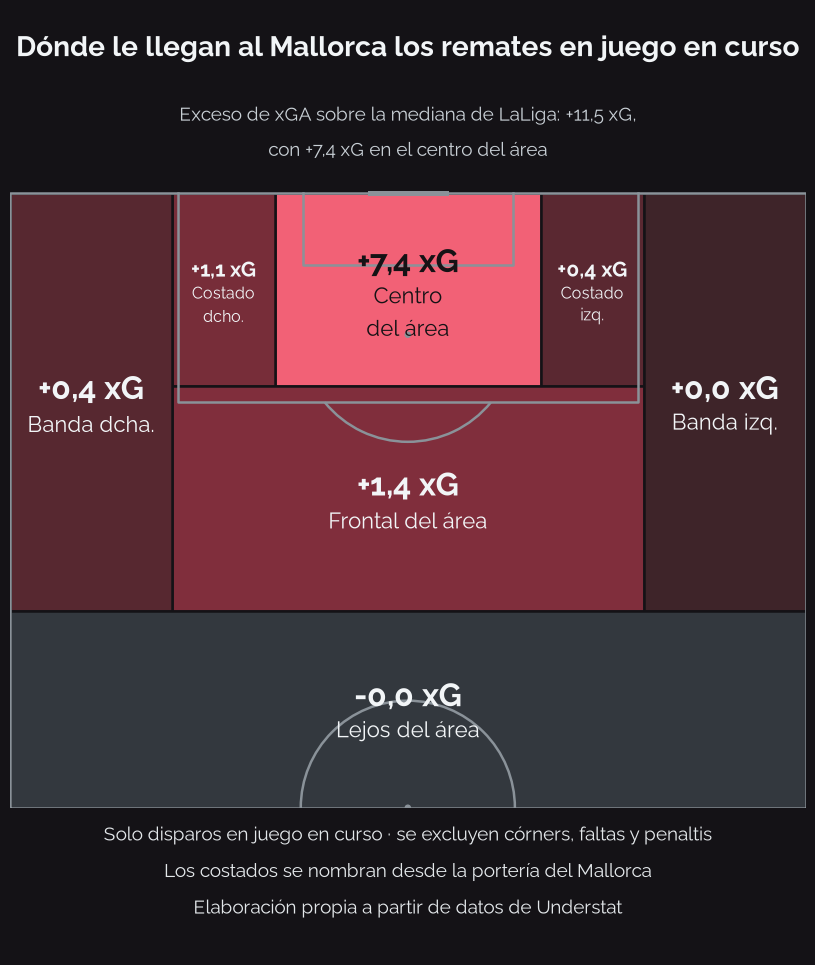

Archivo: images\figura_05_zonas_concedidas_oscura.png
Modificado: Tue Nov 10 16:58:41 2026 | 178 KB


In [14]:
# ============================================================
# FIGURA 5 - VERSION OSCURA PARA SLIDE DEL VIDEO
# Notebook: 05_visualizaciones.ipynb (celda debajo de la anterior)
# ============================================================
import os, time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from mplsoccer import VerticalPitch

CLARO        = "#F2F5F7"
CLARO_SUAVE  = "#C8CFD5"
FONDO_PREVIA = "#141216"
LINEA_OSC    = "#8A9299"
NEUTRO_OSC   = "#33383E"

RUTA_OSC = os.path.join(IMAGES, NOMBRE.replace(".png", "_oscura.png"))
CMAP_OSC = LinearSegmentedColormap.from_list("osc", ["#3A2328", "#A33446", "#F26176"])

def color_osc(v):
    if v <= 0 or max_exceso <= 0:
        return NEUTRO_OSC, CLARO
    t = (v / max_exceso) ** 0.65
    r, g, b, _ = CMAP_OSC(t)
    return (r, g, b), ("#151215" if t >= 0.78 else CLARO)

campo = VerticalPitch(pitch_type="opta", half=True,
                      pad_top=PAD_TOP, pad_bottom=0, pad_left=0, pad_right=0,
                      line_color=LINEA_OSC, linewidth=1.8,
                      pitch_color=FONDO_PREVIA, goal_type="line")
fig, ejes = campo.grid(figheight=FIGH, title_height=0.175,
                       endnote_height=0.145, grid_height=GRID_H,
                       grid_width=0.96, axis=False)
fig.patch.set_facecolor(FONDO_PREVIA)   # solo para verla aqui
ax = ejes["pitch"]
for nombre_eje in ejes:
    ejes[nombre_eje].patch.set_alpha(0)

for z in ZONAS:
    v = float(exceso.get(z["n"], 0.0))
    relleno, tinta = color_osc(v)
    verts = np.array([[z["x0"], z["y0"]], [z["x1"], z["y0"]],
                      [z["x1"], z["y1"]], [z["x0"], z["y1"]]])
    campo.polygon([verts], ax=ax, fc=relleno, ec=FONDO_PREVIA, lw=1.8, zorder=0.5)

    valor_txt = f"{esp(v)} xG"
    f_val, f_nom, altura, n_lin = tamanos(z["n"], valor_txt, z, 23.0, 16.0)
    cx, cy = (z["x0"] + z["x1"]) / 2, (z["y0"] + z["y1"]) / 2
    techo = cx + (altura / 2) / PT_X
    campo.annotate(valor_txt, xy=(techo - (f_val * 1.35 / 2) / PT_X, cy), ax=ax,
                   ha="center", va="center", fontsize=f_val,
                   fontweight="bold", color=tinta, zorder=3)
    campo.annotate(z["n"], xy=(techo - (f_val * 1.35 + f_nom * 1.30 * n_lin / 2) / PT_X, cy),
                   ax=ax, ha="center", va="center", fontsize=f_nom,
                   color=tinta, zorder=3, linespacing=1.25)

ejes["title"].text(0.5, 0.78, "Dónde le llegan al Mallorca los remates en juego en curso",
                   ha="center", va="center", fontsize=20, fontweight="bold", color=CLARO)
ejes["title"].text(0.5, 0.26,
    f"Exceso de xGA sobre la mediana de LaLiga: {esp(exc_total)} xG,\n"
    f"con {esp(exc_centro)} xG en el centro del área",
    ha="center", va="center", fontsize=14, color=CLARO_SUAVE, linespacing=1.5)

ejes["endnote"].text(0.5, 1,
    "Solo disparos en juego en curso · se excluyen córners, faltas y penaltis\n"
    "Los costados se nombran desde la portería del Mallorca\n"
    "Elaboración propia a partir de datos de Understat",
    ha="center", va="top", fontsize=14, color="#E3E7EA", linespacing=1.6)

fig.savefig(RUTA_OSC, dpi=200, transparent=True)
plt.show()

print("Archivo:", os.path.relpath(RUTA_OSC))
print("Modificado:", time.ctime(os.path.getmtime(RUTA_OSC)),
      "|", round(os.path.getsize(RUTA_OSC)/1024), "KB")

## Figura 6 · Los centrales

Compara a los tres centrales habituales del Mallorca con el grupo de control: los 21 centrales de los seis equipos que defendian mas bajo de LaLiga. Comparar contra toda la liga seria injusto, porque en un bloque bajo se intercepta menos por diseno.

Centrales en el grupo de control: 21
Centrales del Mallorca dibujados: ['Martin Valjent', 'Antonio Raíllo', 'David López']



AJUSTE DE TEXTOS


  titulo   -> 19.0 pt


  subtitulo-> 14.0 pt


  pie      -> 14.0 pt


  margen izquierdo correcto (sobran 12 px)


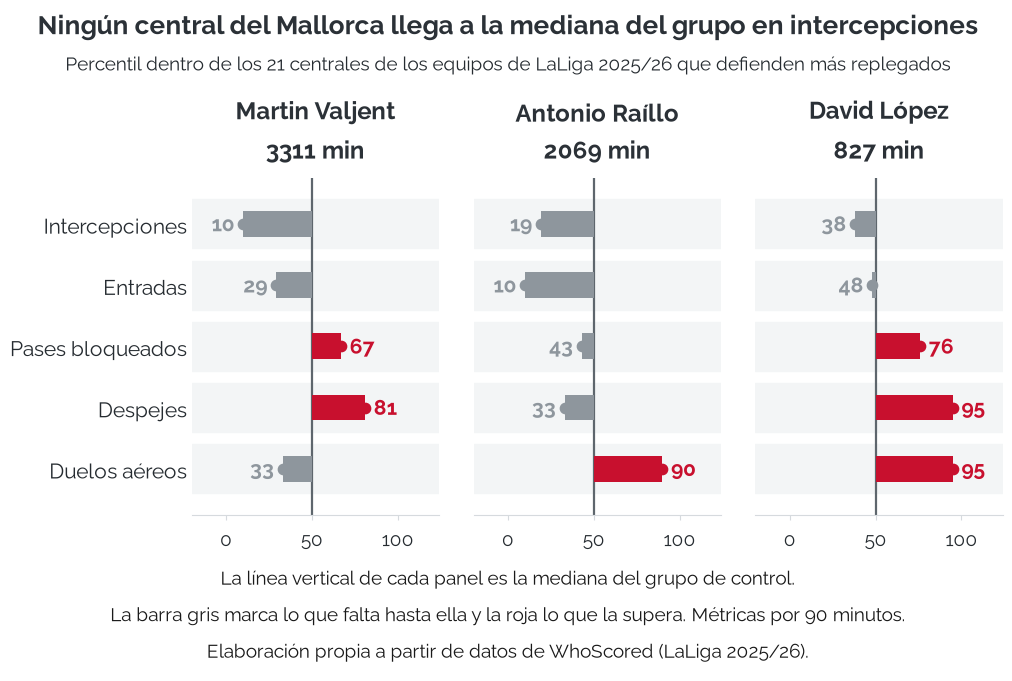


PERCENTILES SOBRE EL GRUPO DE CONTROL
JUGADOR               Intercepciones          Entradas  Pases bloqueados          Despejes     Duelos aéreos
Martin Valjent                    10                29                67                81                33
Antonio Raíllo                    19                10                43                33                90
David López                       38                48                76                95                95

COMPROBACION CONTRA EL TEXTO (intercepciones)
  Martin Valjent     figura: 10   texto: 10  -> OK
  Antonio Raíllo     figura: 19   texto: 19  -> OK
  David López        figura: 38   texto: 38  -> OK

Archivo: images\figura_06_centrales.png
Modificado: Tue Nov 10 16:58:44 2026 | 212 KB


In [15]:
# ============================================================
# FIGURA 6 - PERFIL DEFENSIVO DE LOS CENTRALES DEL MALLORCA (VERSION DOCUMENTO)
# Notebook: 05_visualizaciones.ipynb
# Mide los textos sobre el lienzo real para que nada quede cortado
# ============================================================
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE = ".." if os.path.isdir("../data") else "."
DATOS  = os.path.join(BASE, "data")
IMAGES = os.path.join(BASE, "images")

GRIS_TITULO = "#2B3137"
GRIS_TEXTO  = "#262C31"
GRIS_PIE    = "#1A1A1A"
GRIS_BANDA  = "#F3F5F6"
GRIS_BARRA  = "#8E969D"
ROJO        = "#C8102E"

MIN_MIN   = 600
N_EQUIPOS = 6
RUTA = os.path.join(IMAGES, "figura_06_centrales.png")

met = pd.read_csv(os.path.join(DATOS, "metricas_jugadores_laliga_2526.csv"))
alt = pd.read_csv(os.path.join(DATOS, "altura_defensiva_laliga_2526.csv")).sort_values("altura_defensiva")

seis = [e.lower() for e in alt.head(N_EQUIPOS)["equipo"]]
ctrl = met[(met["posicion"] == "central") & (met["minutes"] >= MIN_MIN) &
           (met["equipo"].astype(str).str.lower().isin(seis))]
mall = met[(met["posicion"] == "central") & (met["minutes"] >= MIN_MIN) &
           (met["equipo"].astype(str).str.lower() == "mallorca")].sort_values("minutes", ascending=False)

print("Centrales en el grupo de control:", len(ctrl))
print("Centrales del Mallorca dibujados:", list(mall["jugador"]))

METRICAS = [
    ("Interception_90",  "Intercepciones"),
    ("Tackle_90",        "Entradas"),
    ("BlockedPass_90",   "Pases bloqueados"),
    ("Clearance_90",     "Despejes"),
    ("Aerial_90",        "Duelos aéreos"),
]

def percentil(serie, valor):
    s = serie.dropna()
    return int(round((s < valor).mean() * 100))

jugadores = [{"nombre": f["jugador"], "min": int(f["minutes"]),
              "pct": [percentil(ctrl[c], f[c]) for c, _ in METRICAS]}
             for _, f in mall.iterrows()]

i_int = [i for i, (c, _) in enumerate(METRICAS) if c == "Interception_90"][0]
TITULO = ("Ningún central del Mallorca llega a la mediana del grupo en intercepciones"
          if all(j["pct"][i_int] < 50 for j in jugadores)
          else "Perfil defensivo de los centrales del RCD Mallorca")
SUBTITULO = (f"Percentil dentro de los {len(ctrl)} centrales de los equipos "
             "de LaLiga 2025/26 que defienden más replegados")
PIE = ("La línea vertical de cada panel es la mediana del grupo de control.\n"
       "La barra gris marca lo que falta hasta ella y la roja lo que la supera. Métricas por 90 minutos.\n"
       "Elaboración propia a partir de datos de WhoScored (LaLiga 2025/26).")

# ---------- figura ----------
n_met, n_jug = len(METRICAS), len(jugadores)
FIGW, FIGH = 10.2, 6.8
fig, ejes = plt.subplots(1, n_jug, figsize=(FIGW, FIGH), sharex=True, sharey=True)
fig.patch.set_facecolor("white")
ejes = np.atleast_1d(ejes).ravel()

for k, (ax, j) in enumerate(zip(ejes, jugadores)):
    ax.set_facecolor("white")
    for i in range(n_met):
        y = n_met - 1 - i
        v = j["pct"][i]
        color = ROJO if v >= 50 else GRIS_BARRA
        ax.axhspan(y - 0.40, y + 0.40, color=GRIS_BANDA, zorder=0)
        ax.barh(y, v - 50, left=50, height=0.42, color=color, zorder=2)
        ax.scatter(v, y, s=55, color=color, zorder=3)
        ax.text(v + (5 if v >= 50 else -5), y, str(v),
                va="center", ha="left" if v >= 50 else "right",
                fontsize=15, fontweight="bold", color=color, zorder=4)

    ax.axvline(50, color="#5E666D", lw=1.6, zorder=1)
    ax.set_title(f"{j['nombre']}\n{j['min']} min", fontsize=17,
                 fontweight="bold", color=GRIS_TITULO, pad=14, linespacing=1.4)
    ax.set_xlim(-20, 124)
    ax.set_ylim(-0.75, n_met - 0.25)
    ax.set_xticks([0, 50, 100])
    ax.set_yticks(range(n_met))
    for lado in ["top", "right", "left"]:
        ax.spines[lado].set_visible(False)
    ax.spines["bottom"].set_color("#D6DADE")
    ax.tick_params(axis="y", length=0)
    ax.tick_params(axis="x", colors="#D6DADE", pad=6)
    ax.set_xticklabels(["0", "50", "100"], fontsize=14, color=GRIS_TEXTO)
    if k == 0:
        ax.set_yticklabels([n for _, n in METRICAS][::-1], fontsize=15, color=GRIS_TEXTO)

t_tit = fig.text(0.5, 0.988, TITULO, ha="center", va="top",
                 fontsize=19, fontweight="bold", color=GRIS_TITULO)
t_sub = fig.text(0.5, 0.925, SUBTITULO, ha="center", va="top",
                 fontsize=14, color=GRIS_TEXTO)
t_pie = fig.text(0.5, 0.015, PIE, ha="center", va="bottom",
                 fontsize=14, color=GRIS_PIE, linespacing=1.6)

plt.subplots_adjust(top=0.740, bottom=0.245, left=0.190, right=0.985, wspace=0.14)

# ---------- medir de verdad y encoger lo que se salga ----------
def encajar(texto, fig, borde=10):
    # Reduce el tamaño de letra hasta que el texto cabe dentro del lienzo
    fig.canvas.draw()
    ancho = fig.bbox.width
    for _ in range(60):
        bb = texto.get_window_extent(fig.canvas.get_renderer())
        if bb.x0 >= borde and bb.x1 <= ancho - borde:
            break
        texto.set_fontsize(texto.get_fontsize() - 0.5)
        fig.canvas.draw()
    return texto.get_fontsize()

print("\nAJUSTE DE TEXTOS")
print("  titulo   ->", encajar(t_tit, fig), "pt")
print("  subtitulo->", encajar(t_sub, fig), "pt")
print("  pie      ->", encajar(t_pie, fig), "pt")

# ---------- comprobar que las etiquetas de la izquierda no se salen ----------
fig.canvas.draw()
r = fig.canvas.get_renderer()
min_x = min(l.get_window_extent(r).x0 for l in ejes[0].get_yticklabels())
if min_x < 10:
    extra = (12 - min_x) / fig.bbox.width
    plt.subplots_adjust(left=0.190 + extra)
    fig.canvas.draw()
    print(f"  margen izquierdo ampliado a {0.190 + extra:.3f}")
else:
    print(f"  margen izquierdo correcto (sobran {min_x:.0f} px)")

# La celda 6 fija savefig.bbox="tight": se deja un margen para que no recorte las etiquetas
fig.savefig(RUTA, dpi=200, facecolor="white", bbox_inches="tight", pad_inches=0.15)
plt.show()

# ---------- control ----------
print("\nPERCENTILES SOBRE EL GRUPO DE CONTROL")
print(f"{'JUGADOR':<18}" + "".join(f"{n[:16]:>18}" for _, n in METRICAS))
for j in jugadores:
    print(f"{j['nombre']:<18}" + "".join(f"{v:>18}" for v in j["pct"]))

esperado = {"Martin Valjent": 10, "Antonio Raíllo": 19, "David López": 38}
print("\nCOMPROBACION CONTRA EL TEXTO (intercepciones)")
for j in jugadores:
    e = esperado.get(j["nombre"])
    print(f"  {j['nombre']:<18} figura: {j['pct'][i_int]:<4} texto: {e}"
          f"  -> {'OK' if e == j['pct'][i_int] else 'REVISAR'}")

print("\nArchivo:", os.path.relpath(RUTA))
print("Modificado:", time.ctime(os.path.getmtime(RUTA)),
      "|", round(os.path.getsize(RUTA)/1024), "KB")

**Figura 6.** Percentiles defensivos de Valjent, Raíllo y David López frente a los 21 centrales de los seis equipos más replegados de LaLiga. Ninguno alcanza la mediana del grupo en intercepciones (percentiles 10, 19 y 38) y los tres la superan en despejes y en duelos aéreos: reaccionan en lugar de anticipar.

*Fuente: elaboración propia a partir de los eventos Opta de WhoScored.*

### Version oscura para el video


AJUSTE DE TEXTOS (oscura)


  titulo   -> 19.5 pt


  subtitulo-> 15.0 pt


  pie      -> 15.0 pt


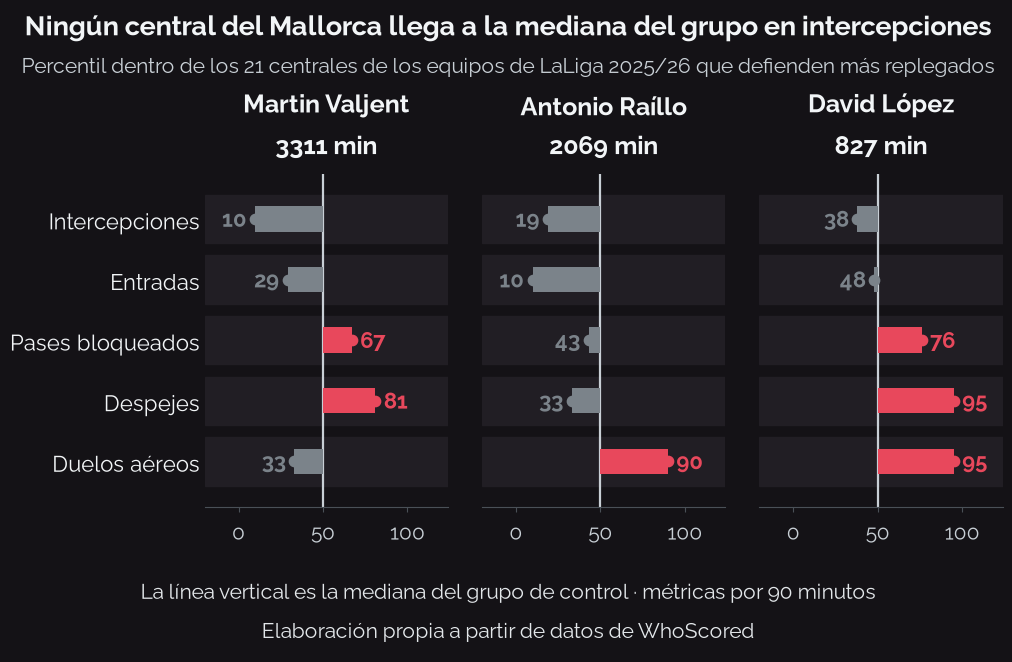

Archivo: images\figura_06_centrales_oscura.png
Modificado: Tue Nov 10 16:58:47 2026 | 170 KB


In [16]:
# ============================================================
# FIGURA 6 - VERSION OSCURA PARA SLIDE DEL VIDEO
# Notebook: 05_visualizaciones.ipynb (celda debajo de la anterior)
# ============================================================
import os, time
import numpy as np
import matplotlib.pyplot as plt

CLARO        = "#F2F5F7"
CLARO_SUAVE  = "#C8CFD5"
ROJO_VIVO    = "#E8485C"
FONDO_PREVIA = "#141216"
BANDA_OSC    = "#211E24"
BARRA_OSC    = "#7B838A"
EJE_OSC      = "#4A5057"

RUTA_OSC = os.path.join(IMAGES, "figura_06_centrales_oscura.png")
PIE_OSC = ("La línea vertical es la mediana del grupo de control · métricas por 90 minutos\n"
           "Elaboración propia a partir de datos de WhoScored")

fig, ejes = plt.subplots(1, n_jug, figsize=(FIGW, FIGH - 0.2), sharex=True, sharey=True)
fig.patch.set_facecolor(FONDO_PREVIA)   # solo para verla aqui
ejes = np.atleast_1d(ejes).ravel()

for k, (ax, j) in enumerate(zip(ejes, jugadores)):
    ax.patch.set_alpha(0)
    for i in range(n_met):
        y = n_met - 1 - i
        v = j["pct"][i]
        color = ROJO_VIVO if v >= 50 else BARRA_OSC
        ax.axhspan(y - 0.40, y + 0.40, color=BANDA_OSC, zorder=0)
        ax.barh(y, v - 50, left=50, height=0.42, color=color, zorder=2)
        ax.scatter(v, y, s=55, color=color, zorder=3)
        ax.text(v + (5 if v >= 50 else -5), y, str(v),
                va="center", ha="left" if v >= 50 else "right",
                fontsize=16, fontweight="bold", color=color, zorder=4)

    ax.axvline(50, color=CLARO_SUAVE, lw=1.6, zorder=1)
    ax.set_title(f"{j['nombre']}\n{j['min']} min", fontsize=18,
                 fontweight="bold", color=CLARO, pad=14, linespacing=1.4)
    ax.set_xlim(-20, 124)
    ax.set_ylim(-0.75, n_met - 0.25)
    ax.set_xticks([0, 50, 100])
    ax.set_yticks(range(n_met))
    for lado in ["top", "right", "left"]:
        ax.spines[lado].set_visible(False)
    ax.spines["bottom"].set_color(EJE_OSC)
    ax.tick_params(axis="y", length=0)
    ax.tick_params(axis="x", colors=EJE_OSC, pad=6)
    ax.set_xticklabels(["0", "50", "100"], fontsize=15, color=CLARO_SUAVE)
    if k == 0:
        ax.set_yticklabels([n for _, n in METRICAS][::-1], fontsize=16, color=CLARO)

t_tit = fig.text(0.5, 0.988, TITULO, ha="center", va="top",
                 fontsize=20, fontweight="bold", color=CLARO)
t_sub = fig.text(0.5, 0.922, SUBTITULO, ha="center", va="top",
                 fontsize=15, color=CLARO_SUAVE)
t_pie = fig.text(0.5, 0.015, PIE_OSC, ha="center", va="bottom",
                 fontsize=15, color="#E3E7EA", linespacing=1.6)

plt.subplots_adjust(top=0.740, bottom=0.235, left=0.190, right=0.985, wspace=0.14)

print("\nAJUSTE DE TEXTOS (oscura)")
print("  titulo   ->", encajar(t_tit, fig), "pt")
print("  subtitulo->", encajar(t_sub, fig), "pt")
print("  pie      ->", encajar(t_pie, fig), "pt")

fig.canvas.draw()
r = fig.canvas.get_renderer()
min_x = min(l.get_window_extent(r).x0 for l in ejes[0].get_yticklabels())
if min_x < 10:
    plt.subplots_adjust(left=0.190 + (12 - min_x) / fig.bbox.width)
    fig.canvas.draw()

# La celda 6 fija savefig.bbox="tight": se deja un margen para que no recorte las etiquetas
fig.savefig(RUTA_OSC, dpi=200, transparent=True, bbox_inches="tight", pad_inches=0.15)
plt.show()

print("Archivo:", os.path.relpath(RUTA_OSC))
print("Modificado:", time.ctime(os.path.getmtime(RUTA_OSC)),
      "|", round(os.path.getsize(RUTA_OSC)/1024), "KB")

## Figura 7 · Los finalistas

Situa a los ocho finalistas de la criba segun lo que aportan y lo que no quitan: intercepciones frente a duelos aereos ganados, con los centrales del Mallorca como referencia.

Candidatos localizados: 8 | no encontrados: []
Medianas del grupo (66 centrales): Interception_90=1.06 | Aerial_90=3.36


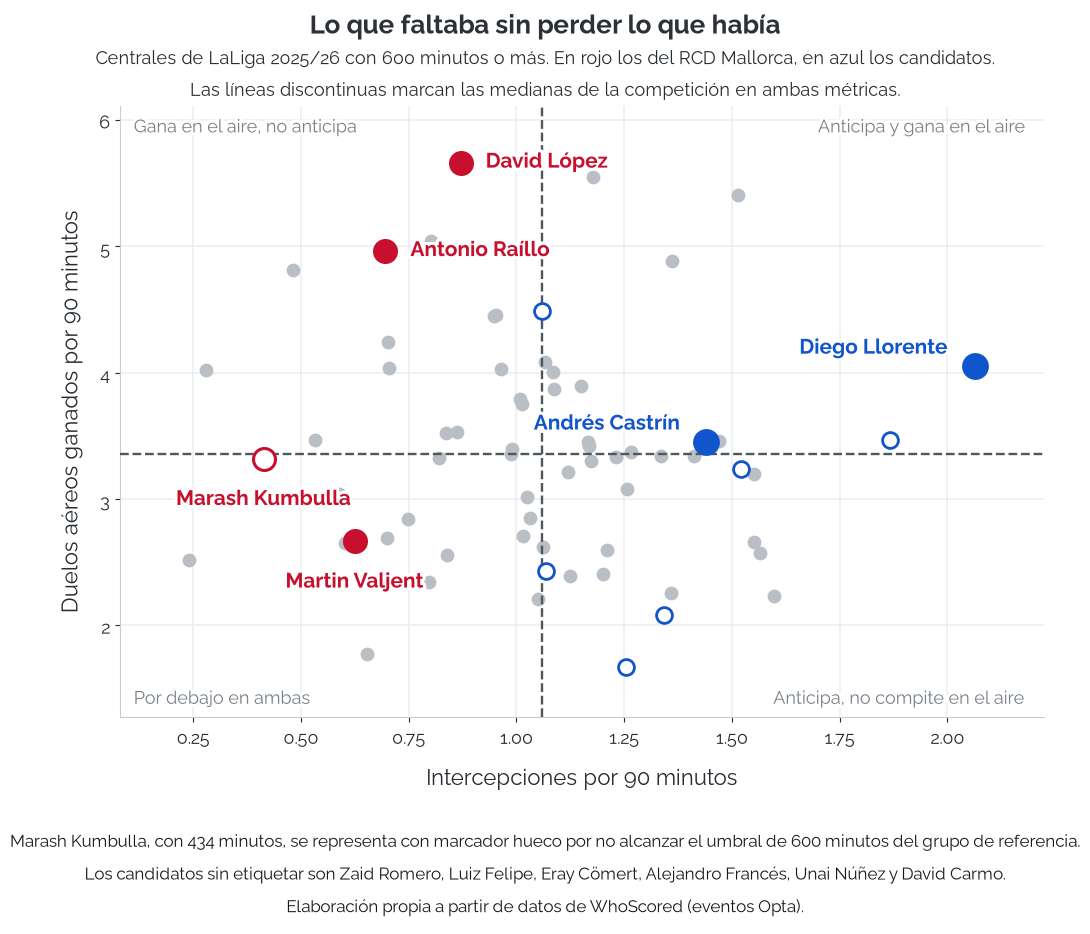


VALORES REPRESENTADOS
JUGADOR               EQUIPO              MIN   INTERC/90   AEREOS/90
Martin Valjent        Mallorca           3311        0.63        2.66
Antonio Raíllo        Mallorca           2069        0.70        4.96
David López           Mallorca            827        0.87        5.66
Marash Kumbulla       Mallorca            434        0.41        3.32
Diego Llorente        Real Betis         1221        2.06        4.05
Andrés Castrín        Sevilla            1251        1.44        3.45
Zaid Romero           Getafe             1350        1.87        3.47
Luiz Felipe           Rayo Vallecano      473        1.52        3.23
Eray Cömert           Valencia           1341        1.34        2.08
Alejandro Francés     Girona             1077        1.25        1.67
Unai Núñez            Valencia            927        1.07        2.43
David Carmo           Real Oviedo        1785        1.06        4.49

Archivo: images\figura_07_llorente.png
Modificado: Tue Nov 10 16:5

In [17]:
# ============================================================
# FIGURA 7 - ANTICIPACION Y JUEGO AEREO: CANDIDATOS VS MALLORCA (VERSION DOCUMENTO)
# Notebook: 05_visualizaciones.ipynb
# Sustituye por completo a la celda anterior de la figura 7
# ============================================================
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe

BASE = ".." if os.path.isdir("../data") else "."
DATOS  = os.path.join(BASE, "data")
IMAGES = os.path.join(BASE, "images")

GRIS_TITULO = "#2B3137"
GRIS_TEXTO  = "#262C31"
GRIS_PIE    = "#1A1A1A"
GRIS_PUNTO  = "#B9BFC5"
GRIS_GRID   = "#EBEEF0"
GRIS_CUAD   = "#7A828A"
ROJO        = "#C8102E"
AZUL        = "#1155CC"

MIN_GRUPO   = 600
MIN_JUGADOR = 400
RUTA = os.path.join(IMAGES, "figura_07_llorente.png")

met = pd.read_csv(os.path.join(DATOS, "metricas_jugadores_laliga_2526.csv"))

CANDIDATOS = ["Diego Llorente", "Andrés Castrín", "Zaid Romero", "Luiz Felipe",
              "Eray Cömert", "Alejandro Francés", "Unai Núñez", "David Carmo"]
DESTACADOS = ["Diego Llorente", "Andrés Castrín"]

X, Y = "Interception_90", "Aerial_90"

def buscar(nombre):
    # Busca por nombre exacto y, si falla, por apellido dentro de los centrales
    m = met[met["jugador"].astype(str).str.lower() == nombre.lower()]
    if len(m) == 0:
        ape = nombre.split()[-1].lower()
        m = met[(met["posicion"] == "central") &
                met["jugador"].astype(str).str.lower().str.contains(ape, na=False)]
    return m.iloc[0] if len(m) else None

grupo = met[(met["posicion"] == "central") & (met["minutes"] >= MIN_GRUPO)]
mall = met[(met["posicion"] == "central") &
           (met["equipo"].astype(str).str.lower() == "mallorca") &
           (met["minutes"] >= MIN_JUGADOR)].sort_values("minutes", ascending=False)

cands, no_encontrados = [], []
for n in CANDIDATOS:
    f = buscar(n)
    if f is None:
        no_encontrados.append(n)
    else:
        cands.append(f)
print("Candidatos localizados:", len(cands), "| no encontrados:", no_encontrados)

nombres_fuera = set(mall["jugador"]) | {c["jugador"] for c in cands}
fondo = grupo[~grupo["jugador"].isin(nombres_fuera)]
med_x, med_y = grupo[X].median(), grupo[Y].median()
print(f"Medianas del grupo ({len(grupo)} centrales): {X}={med_x:.2f} | {Y}={med_y:.2f}")

# ---------- figura ----------
fig, ax = plt.subplots(figsize=(10.5, 9.4))
fig.patch.set_facecolor("white")
ax.set_facecolor("white")
ax.grid(color=GRIS_GRID, lw=1.1, zorder=0)
ax.set_axisbelow(True)

ax.scatter(fondo[X], fondo[Y], s=80, color=GRIS_PUNTO, zorder=2)

for f in cands:
    destacado = f["jugador"] in DESTACADOS
    ax.scatter(f[X], f[Y], s=300 if destacado else 130,
               color=AZUL if destacado else "white",
               edgecolor=AZUL, linewidth=2.0, zorder=4)

for _, f in mall.iterrows():
    completo = f["minutes"] >= MIN_GRUPO
    ax.scatter(f[X], f[Y], s=250,
               color=ROJO if completo else "white",
               edgecolor=ROJO, linewidth=2.2, zorder=5)

ax.axvline(med_x, color="#4F575E", lw=1.7, ls="--", zorder=3)
ax.axhline(med_y, color="#4F575E", lw=1.7, ls="--", zorder=3)

# Margenes extra para que ninguna etiqueta se salga
todos_x = pd.concat([fondo[X], mall[X], pd.Series([c[X] for c in cands])])
todos_y = pd.concat([fondo[Y], mall[Y], pd.Series([c[Y] for c in cands])])
ax.set_xlim(todos_x.min() - 0.16, todos_x.max() + 0.16)
ax.set_ylim(todos_y.min() - 0.40, todos_y.max() + 0.45)

DESPLAZA = {
    "Diego Llorente":  (-18,  14, "right"),
    "Andrés Castrín":  (-18,  14, "right"),
    "David López":     ( 18,   2, "left"),
    "Antonio Raíllo":  ( 18,   2, "left"),
    "Martin Valjent":  (  0, -28, "center"),
    "Marash Kumbulla": (  0, -28, "center"),
}
HALO = [pe.withStroke(linewidth=4.5, foreground="white")]

etiquetados = [(f, ROJO) for _, f in mall.iterrows()] + \
              [(f, AZUL) for f in cands if f["jugador"] in DESTACADOS]
for f, color in etiquetados:
    dx, dy, ha = DESPLAZA.get(f["jugador"], (18, 2, "left"))
    ax.annotate(f["jugador"], xy=(f[X], f[Y]), xytext=(dx, dy),
                textcoords="offset points", ha=ha, va="center",
                fontsize=15, fontweight="bold", color=color,
                zorder=6, path_effects=HALO)

for px, py, ha, va, txt in [
        (0.015, 0.985, "left",  "top",    "Gana en el aire, no anticipa"),
        (0.985, 0.985, "right", "top",    "Anticipa y gana en el aire"),
        (0.015, 0.015, "left",  "bottom", "Por debajo en ambas"),
        (0.985, 0.015, "right", "bottom", "Anticipa, no compite en el aire")]:
    ax.text(px, py, txt, transform=ax.transAxes, ha=ha, va=va,
            fontsize=13, color=GRIS_CUAD, zorder=6, path_effects=HALO)

ax.set_xlabel("Intercepciones por 90 minutos", fontsize=15.5, color=GRIS_TEXTO, labelpad=12)
ax.set_ylabel("Duelos aéreos ganados por 90 minutos", fontsize=15.5, color=GRIS_TEXTO, labelpad=12)
ax.tick_params(labelsize=13, colors=GRIS_TEXTO)
for lado in ["top", "right"]:
    ax.spines[lado].set_visible(False)
for lado in ["left", "bottom"]:
    ax.spines[lado].set_color("#C7CCD1")

fig.text(0.5, 0.988, "Lo que faltaba sin perder lo que había",
         ha="center", va="top", fontsize=18.5, fontweight="bold", color=GRIS_TITULO)
fig.text(0.5, 0.952,
         "Centrales de LaLiga 2025/26 con 600 minutos o más. En rojo los del RCD Mallorca, en azul los candidatos.\n"
         "Las líneas discontinuas marcan las medianas de la competición en ambas métricas.",
         ha="center", va="top", fontsize=13, color=GRIS_TEXTO, linespacing=1.5)

otros = [c["jugador"] for c in cands if c["jugador"] not in DESTACADOS]
min_kum = mall.loc[mall["jugador"].str.contains("Kumbulla", na=False), "minutes"]
txt_kum = (f"Marash Kumbulla, con {int(min_kum.iloc[0])} minutos, se representa con marcador hueco "
           "por no alcanzar el umbral de 600 minutos del grupo de referencia.\n") if len(min_kum) else ""

fig.text(0.5, 0.015,
         txt_kum +
         f"Los candidatos sin etiquetar son {', '.join(otros[:-1])} y {otros[-1]}.\n"
         "Elaboración propia a partir de datos de WhoScored (eventos Opta).",
         ha="center", va="bottom", fontsize=12.5, color=GRIS_PIE, linespacing=1.6)

plt.subplots_adjust(top=0.885, bottom=0.235, left=0.095, right=0.975)

fig.savefig(RUTA, dpi=200, facecolor="white")
plt.show()

# ---------- control ----------
print("\nVALORES REPRESENTADOS")
print(f"{'JUGADOR':<22}{'EQUIPO':<16}{'MIN':>7}{'INTERC/90':>12}{'AEREOS/90':>12}")
for _, f in mall.iterrows():
    print(f"{f['jugador']:<22}{str(f['equipo']):<16}{int(f['minutes']):>7}{f[X]:>12.2f}{f[Y]:>12.2f}")
for f in cands:
    print(f"{f['jugador']:<22}{str(f['equipo']):<16}{int(f['minutes']):>7}{f[X]:>12.2f}{f[Y]:>12.2f}")
print("\nArchivo:", os.path.relpath(RUTA))
print("Modificado:", time.ctime(os.path.getmtime(RUTA)),
      "|", round(os.path.getsize(RUTA)/1024), "KB")

**Figura 7.** Los ocho candidatos de la criba situados por intercepciones y duelos aéreos ganados por 90 minutos, con los centrales del RCD Mallorca como referencia. Diego Llorente entra en el cuadrante superior derecho con **2,06 intercepciones por 90**, el triple que Valjent, sin renunciar a la solidez aérea (4,07 duelos aéreos ganados).

*Fuente: elaboración propia a partir de los eventos Opta de WhoScored.*

### Version oscura para el video

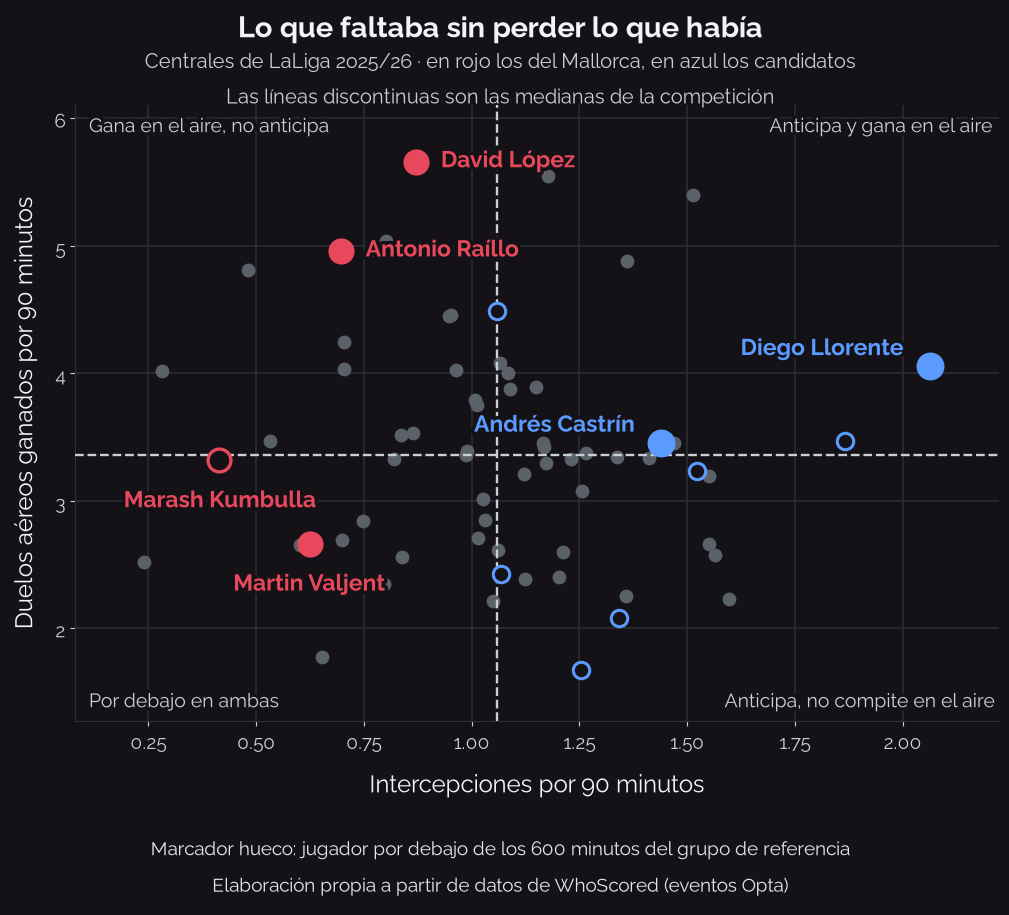

Archivo: images\figura_07_llorente_oscura.png
Modificado: Tue Nov 10 16:58:50 2026 | 302 KB


In [18]:
# ============================================================
# FIGURA 7 - VERSION OSCURA PARA SLIDE DEL VIDEO
# Notebook: 05_visualizaciones.ipynb (celda debajo de la anterior)
# Guarda figura_07_llorente_oscura.png con fondo transparente
# ============================================================
import os, time
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe

CLARO        = "#F2F5F7"
CLARO_SUAVE  = "#C8CFD5"
ROJO_VIVO    = "#E8485C"
AZUL_VIVO    = "#5B9BFF"
FONDO_PREVIA = "#141216"
PUNTO_OSC    = "#5A6168"
GRID_OSC     = "#2C3035"

RUTA_OSC = os.path.join(IMAGES, "figura_07_llorente_oscura.png")

fig, ax = plt.subplots(figsize=(10.5, 9.2))
fig.patch.set_facecolor(FONDO_PREVIA)   # solo para verla aqui
ax.patch.set_alpha(0)
ax.grid(color=GRID_OSC, lw=1.1, zorder=0)
ax.set_axisbelow(True)

ax.scatter(fondo[X], fondo[Y], s=80, color=PUNTO_OSC, zorder=2)

for f in cands:
    destacado = f["jugador"] in DESTACADOS
    ax.scatter(f[X], f[Y], s=320 if destacado else 140,
               color=AZUL_VIVO if destacado else FONDO_PREVIA,
               edgecolor=AZUL_VIVO, linewidth=2.2, zorder=4)

for _, f in mall.iterrows():
    completo = f["minutes"] >= MIN_GRUPO
    ax.scatter(f[X], f[Y], s=270,
               color=ROJO_VIVO if completo else FONDO_PREVIA,
               edgecolor=ROJO_VIVO, linewidth=2.4, zorder=5)

ax.axvline(med_x, color=CLARO_SUAVE, lw=1.7, ls="--", zorder=3)
ax.axhline(med_y, color=CLARO_SUAVE, lw=1.7, ls="--", zorder=3)

ax.set_xlim(todos_x.min() - 0.16, todos_x.max() + 0.16)
ax.set_ylim(todos_y.min() - 0.40, todos_y.max() + 0.45)

HALO_OSC = [pe.withStroke(linewidth=5, foreground=FONDO_PREVIA)]

for f, color in [(f, ROJO_VIVO) for _, f in mall.iterrows()] + \
                [(f, AZUL_VIVO) for f in cands if f["jugador"] in DESTACADOS]:
    dx, dy, ha = DESPLAZA.get(f["jugador"], (18, 2, "left"))
    ax.annotate(f["jugador"], xy=(f[X], f[Y]), xytext=(dx, dy),
                textcoords="offset points", ha=ha, va="center",
                fontsize=16.5, fontweight="bold", color=color,
                zorder=6, path_effects=HALO_OSC)

for px, py, ha, va, txt in [
        (0.015, 0.985, "left",  "top",    "Gana en el aire, no anticipa"),
        (0.985, 0.985, "right", "top",    "Anticipa y gana en el aire"),
        (0.015, 0.015, "left",  "bottom", "Por debajo en ambas"),
        (0.985, 0.015, "right", "bottom", "Anticipa, no compite en el aire")]:
    ax.text(px, py, txt, transform=ax.transAxes, ha=ha, va=va,
            fontsize=14, color=CLARO_SUAVE, zorder=6, path_effects=HALO_OSC)

ax.set_xlabel("Intercepciones por 90 minutos", fontsize=17, color=CLARO, labelpad=12)
ax.set_ylabel("Duelos aéreos ganados por 90 minutos", fontsize=17, color=CLARO, labelpad=12)
ax.tick_params(labelsize=14, colors=CLARO_SUAVE)
for lado in ["top", "right"]:
    ax.spines[lado].set_visible(False)
for lado in ["left", "bottom"]:
    ax.spines[lado].set_color(GRID_OSC)

fig.text(0.5, 0.988, "Lo que faltaba sin perder lo que había",
         ha="center", va="top", fontsize=21, fontweight="bold", color=CLARO)
fig.text(0.5, 0.950,
         "Centrales de LaLiga 2025/26 · en rojo los del Mallorca, en azul los candidatos\n"
         "Las líneas discontinuas son las medianas de la competición",
         ha="center", va="top", fontsize=14.5, color=CLARO_SUAVE, linespacing=1.5)

fig.text(0.5, 0.015,
         "Marcador hueco: jugador por debajo de los 600 minutos del grupo de referencia\n"
         "Elaboración propia a partir de datos de WhoScored (eventos Opta)",
         ha="center", va="bottom", fontsize=14, color="#E3E7EA", linespacing=1.6)

plt.subplots_adjust(top=0.885, bottom=0.215, left=0.095, right=0.975)

fig.savefig(RUTA_OSC, dpi=200, transparent=True)
plt.show()

print("Archivo:", os.path.relpath(RUTA_OSC))
print("Modificado:", time.ctime(os.path.getmtime(RUTA_OSC)),
      "|", round(os.path.getsize(RUTA_OSC)/1024), "KB")